# Closure tests — part 1: refolding + statistical closure

Shared plotting code lives in `closure_tests_common.py`; this notebook only loads inputs and makes the plots.

In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

import matplotlib.pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
from matplotlib.ticker import MaxNLocator, NullFormatter

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [2]:
import sys
sys.path.insert(0, '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/')

import closure_tests_common as ctc
from closure_tests_common import *   # plotting functions + binning constants (incl. rebinned R_L binning)

inp = ctc.load_inputs()

# aliases so the section cells below work unchanged
labels, n_iter = inp.labels, inp.n_iter
binning, bincenters, binwidths = inp.binning, inp.bincenters, inp.binwidths
L_colors, L_markers = inp.L_colors, inp.L_markers

f_closure_tests = inp.f_closure_tests
f_closure_tests_1D = inp.f_closure_tests_1D
h3_truth = inp.h3_truth
h3_raw, h1_raw = inp.h3_raw, inp.h1_raw
h3_unfolded, h3_refolded = inp.h3_unfolded, inp.h3_refolded
h1_unfolded, h1_refolded = inp.h1_unfolded, inp.h1_refolded
h3_stat_unfolded_mc = inp.h3_stat_unfolded_mc

### Single-pT-bin EEC panel

Use `plot_closure_test_fullEEC_ptbin(...)` for one pT bin, with the same EEC/ratio styling as the 8-panel plot and a legend beside it. Pass the same histogram and plotting arguments as `plot_closure_test_fullEEC_ptbins(...)`, plus `pt_bin_index` and `closure_label` (for example, `Statistical closure`). The pT-bin index is zero-based: `1` selects 20-40 GeV. The function also accepts `high_pt` so bins at/above 100 GeV use the rebinned R_L input.

## Refolding Test

Take the unfolded solution --> multiply it by the original RM --> the resulting *refolded* distribution gets compared to original detector-level spectrum

Need:
- unfolded data distribution (truth level data)
- original RM
- original det-level data

In [3]:
proj = lambda a : a.values()
proj3D = lambda a : [projectionX(a.values()), projectionY(a.values()), projectionZ(a.values())]
proj3D_err = lambda a : [projectionX(a.errors()), projectionY(a.errors()), projectionZ(a.errors())]


# Extract 1D array values
# Returns y3_raw (values for one histogram), and y3_refolded (array of histograms for each iteration)
def get_yvals_for_label(lab):
    y3_raw = proj3D(h3_raw[lab])
    y3_unfolded = [proj3D(a) for a in h3_unfolded[lab]]
    y3_unfolded_err = [proj3D_err(a) for a in h3_unfolded[lab]]
    y3_refolded = [proj3D(a) for a in h3_refolded[lab]]
    y3_refolded_err = [proj3D_err(a) for a in h3_refolded[lab]]

    return y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err

# Extract 1D values directly from your h1_refolded list
y1_refolded = [proj(a) for a in h1_refolded]
y1_refolded_err = [h.errors() for h in h1_refolded[:n_iter]]

# y_raw = h1_raw.values() if hasattr(h1_raw, "values") else h1_raw
# y_unfolded = [proj(a) for a in h1_unfolded]
# y_refolded = [proj(a) for a in h1_refolded]

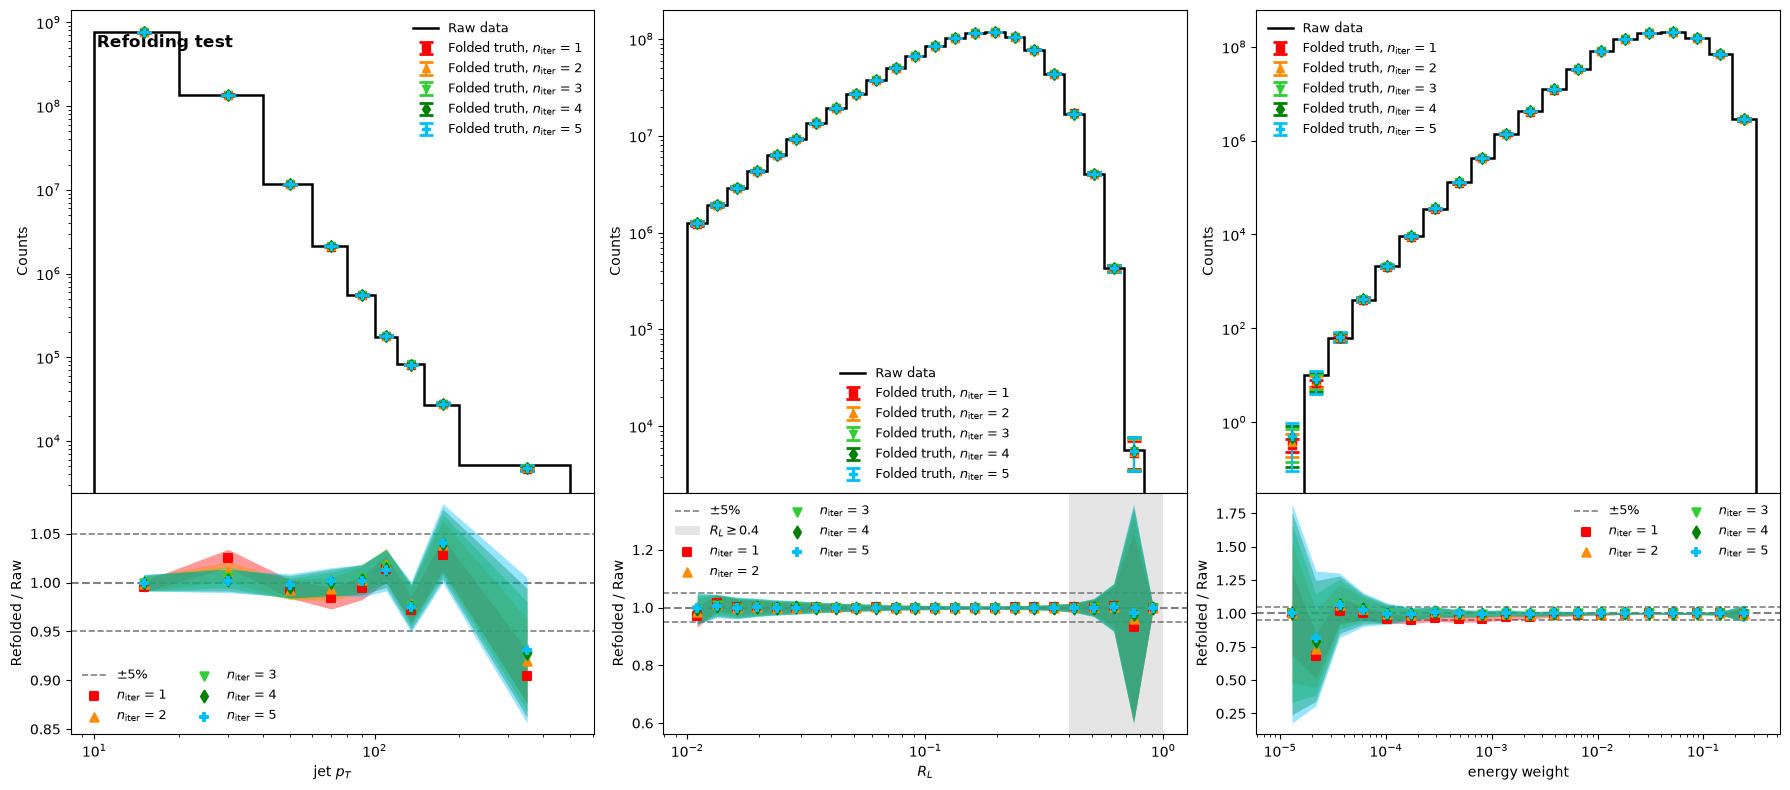

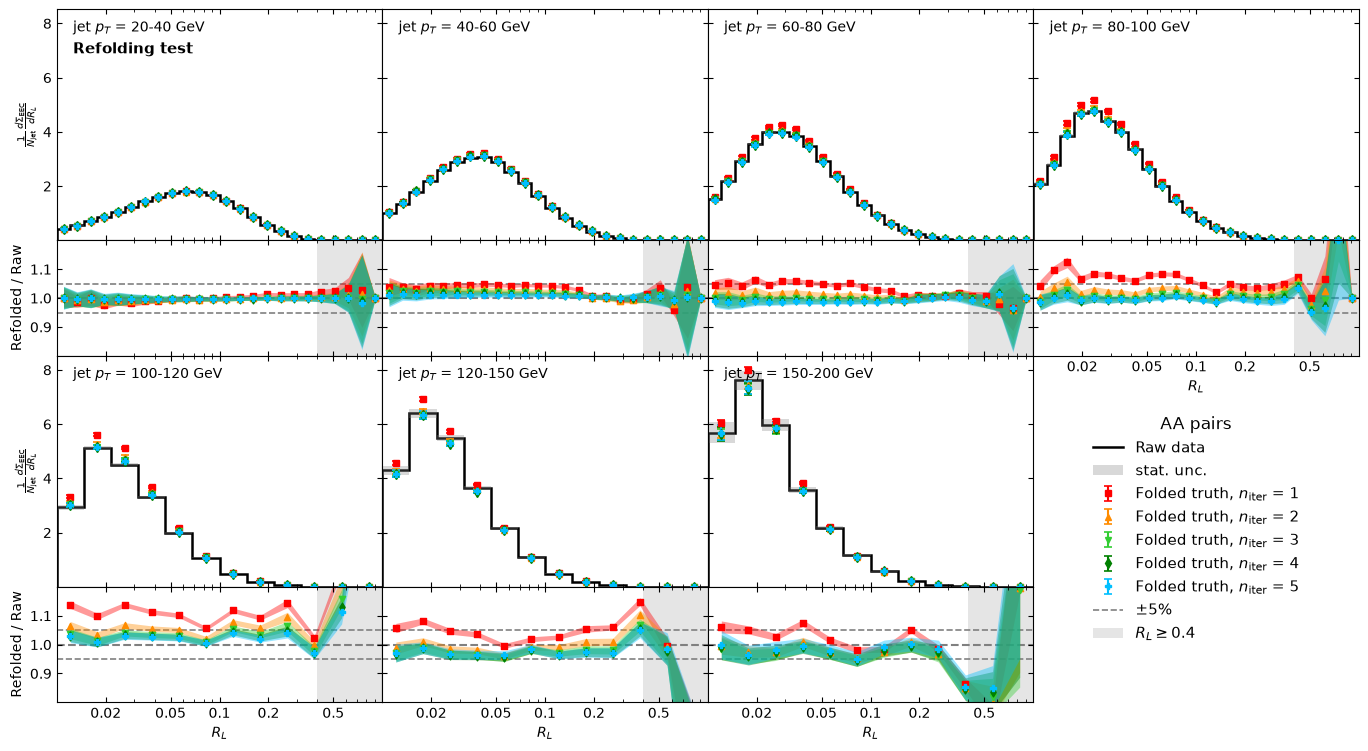

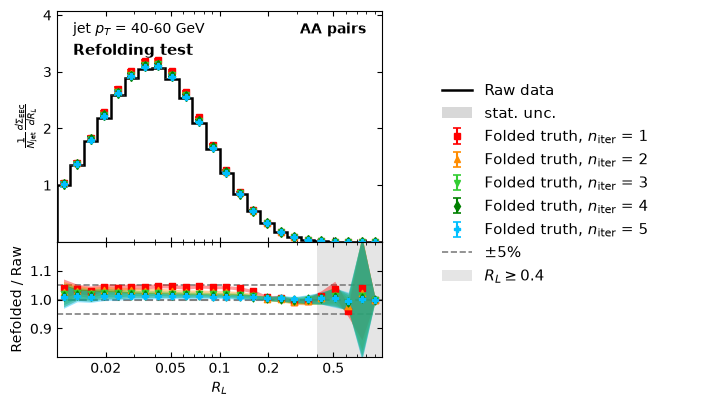

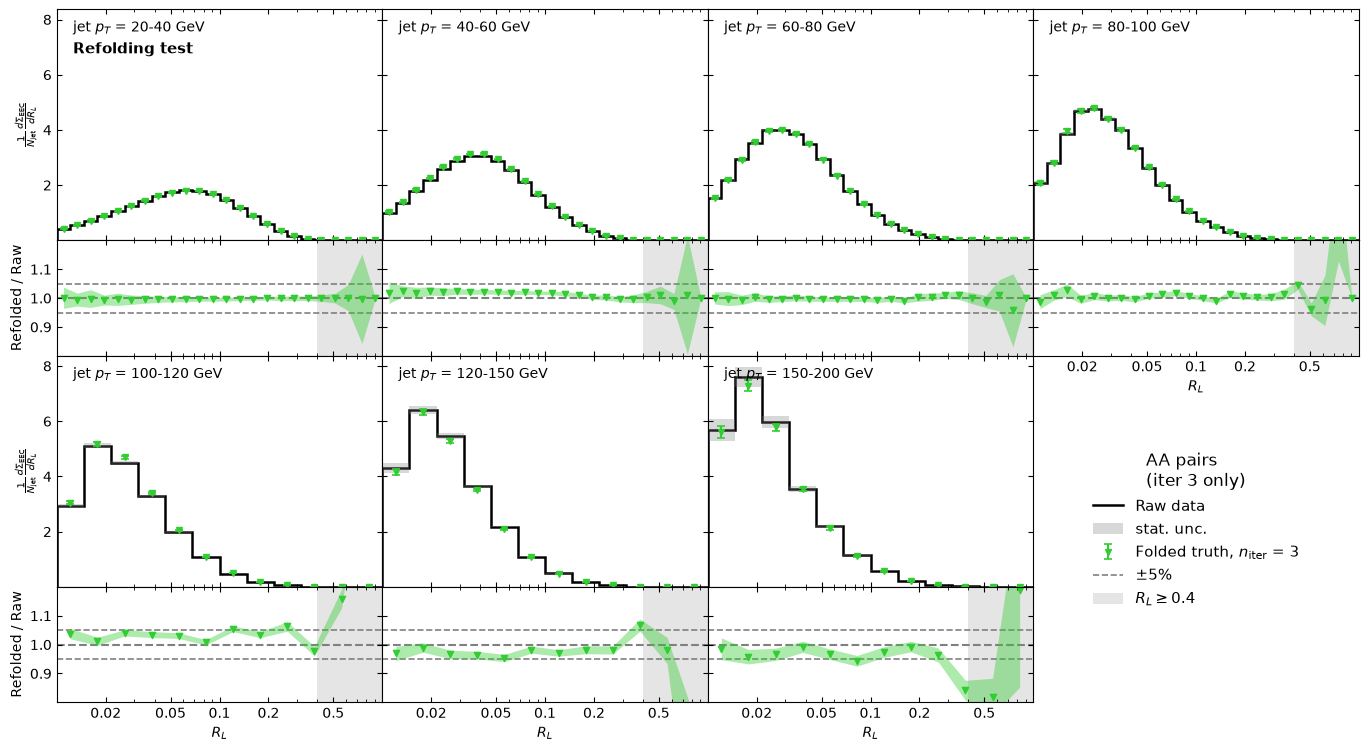

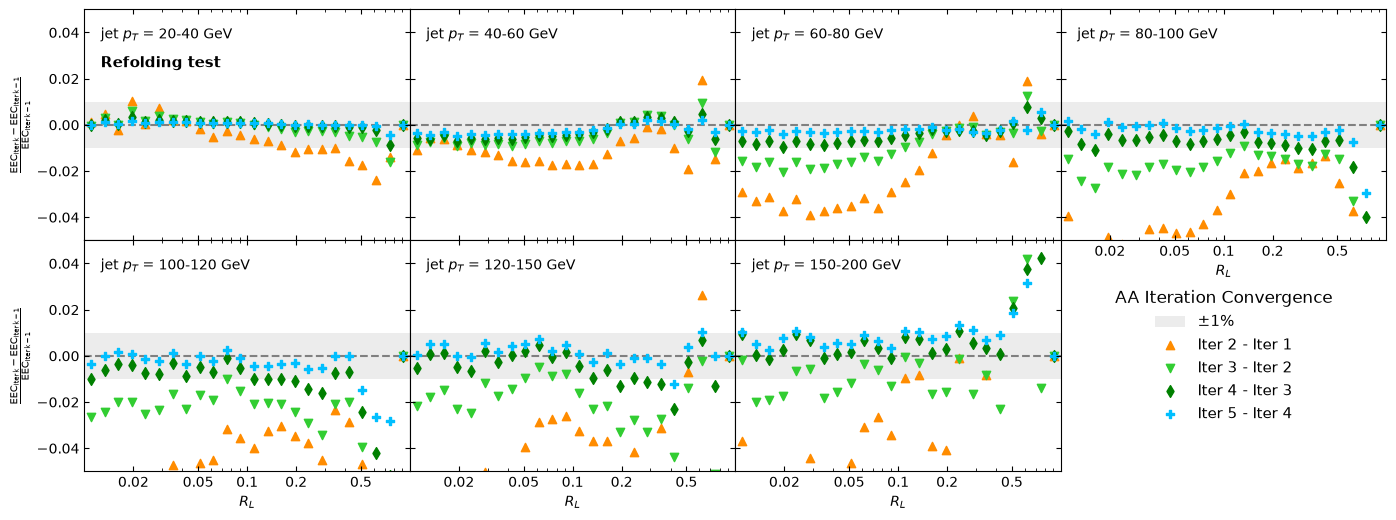

In [4]:
# Data refolding - AA - w/ purity corrections
lab = "AA"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False, closure_label="Refolding test")

# fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")

# differential pT bins (>= 100 GeV taken from the RL-rebinned files)
fig_ptbins = plot_closure_test_fullEEC_ptbins(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                              bincenters, binning, binwidths, L_colors, L_markers,
                                              unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                              high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")
fig_ptbins = plot_closure_test_fullEEC_ptbin(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                             bincenters, binning, binwidths, L_colors, L_markers, pt_bin_index=2,
                                             unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                             high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")

# same differential-pT plot, but only iteration 3
fig_ptbins_iter3 = plot_closure_test_fullEEC_ptbins_singleiter(
    lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
    bincenters, binning, binwidths, L_colors, L_markers,
    iteration=3, unfolding=False, label_ref="Raw data", label_test="Folded truth",
    high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test",
    extralabel="(iter 3 only)")

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")


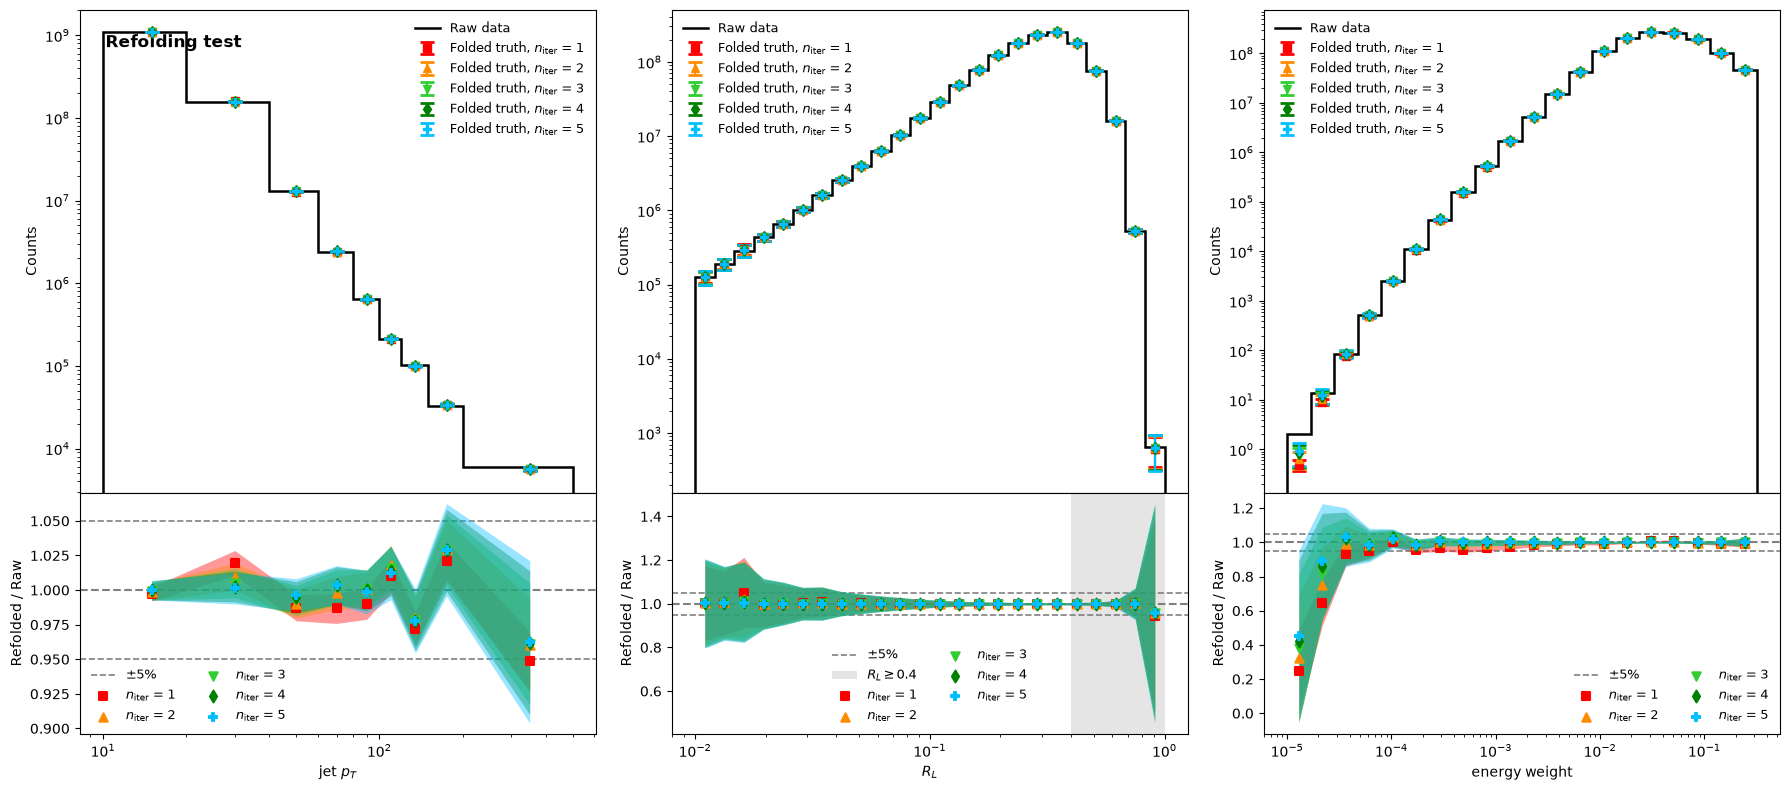

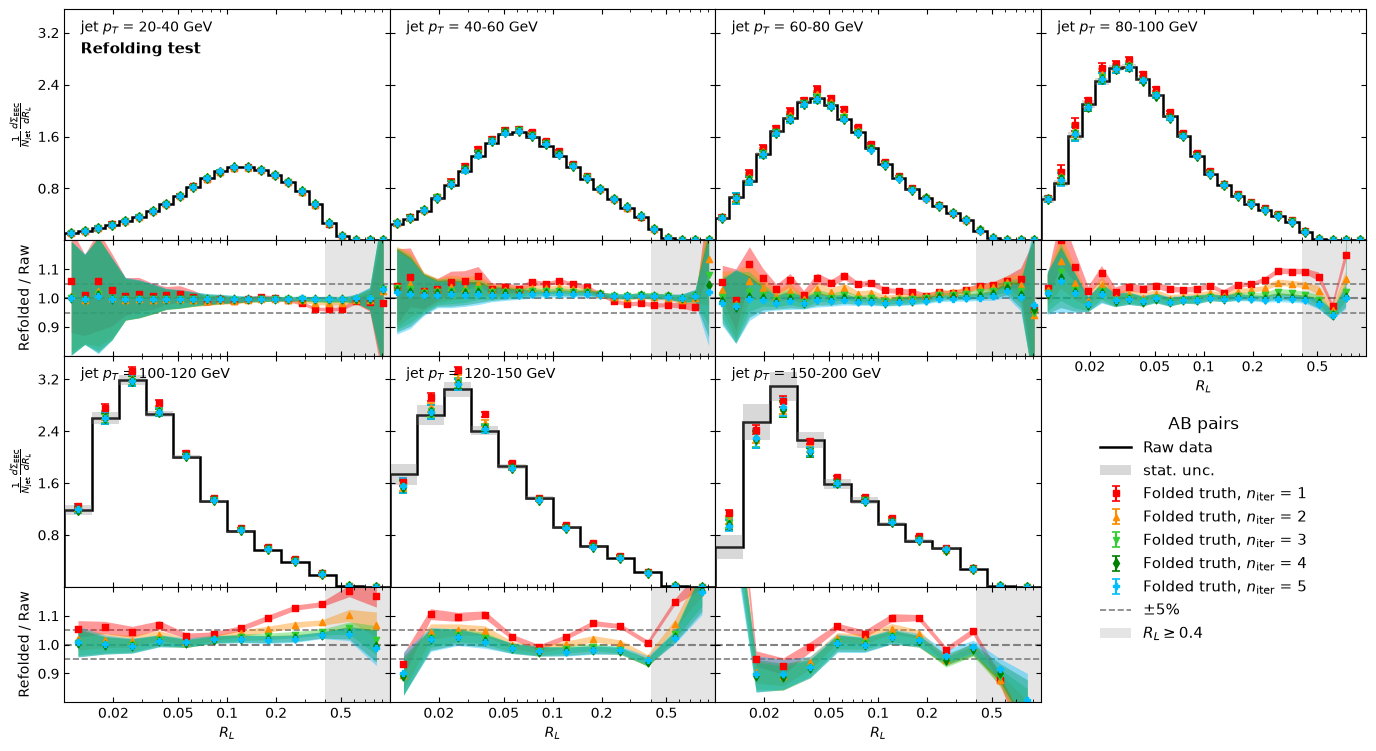

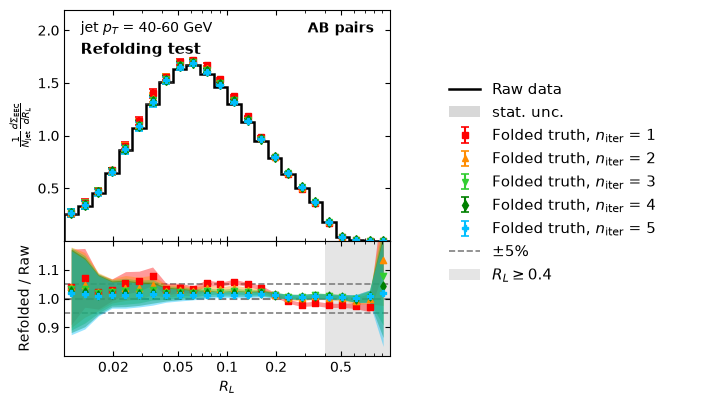

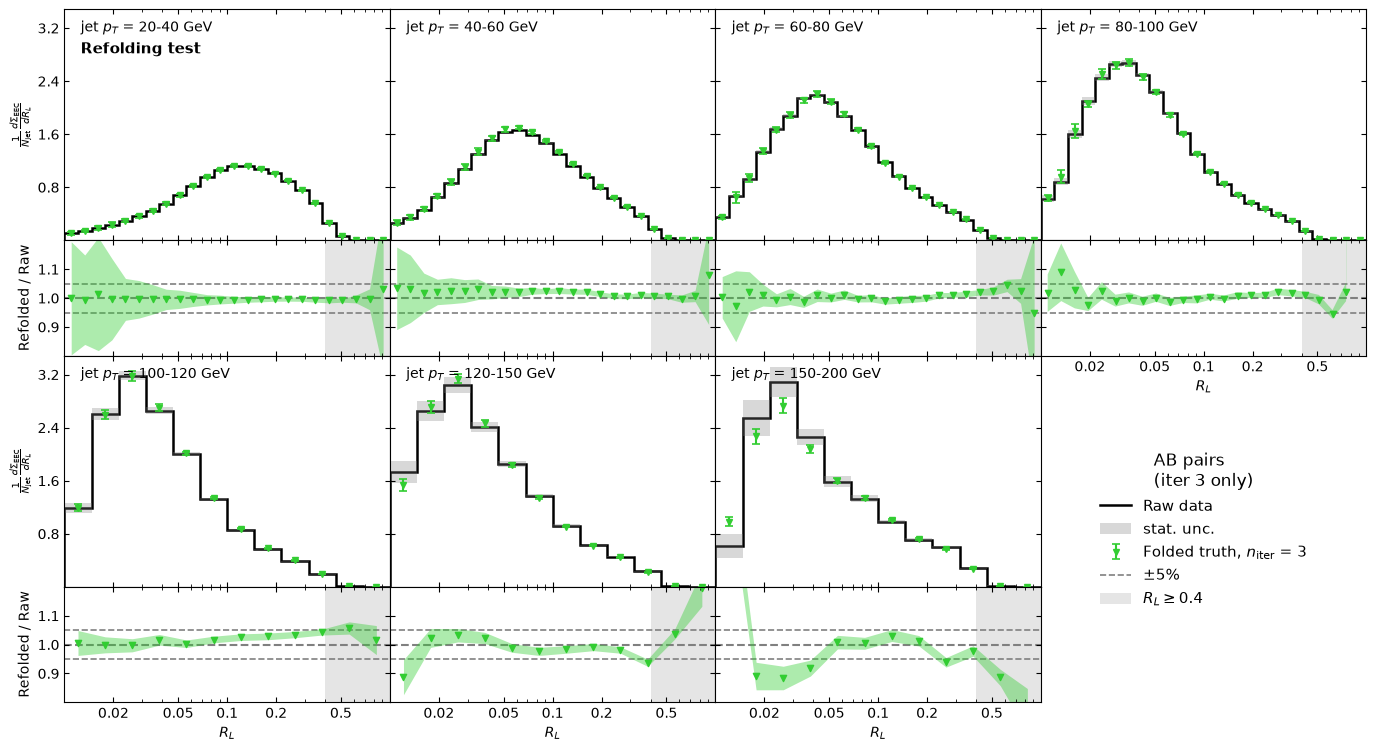

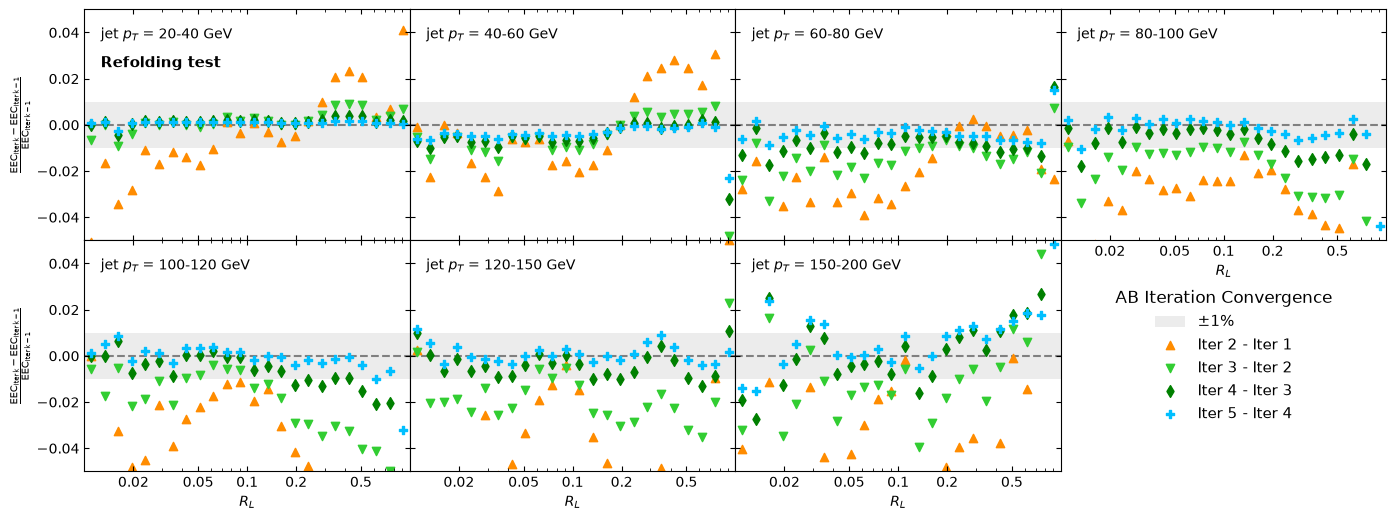

In [5]:
# Data refolding - AB - w/ purity corrections
lab = "AB"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False, closure_label="Refolding test")

# fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")

# differential pT bins (>= 100 GeV taken from the RL-rebinned files)
fig_ptbins = plot_closure_test_fullEEC_ptbins(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                              bincenters, binning, binwidths, L_colors, L_markers,
                                              unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                              high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")
fig_ptbins = plot_closure_test_fullEEC_ptbin(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                             bincenters, binning, binwidths, L_colors, L_markers, pt_bin_index=2,
                                             unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                             high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")

# same differential-pT plot, but only iteration 3
fig_ptbins_iter3 = plot_closure_test_fullEEC_ptbins_singleiter(
    lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
    bincenters, binning, binwidths, L_colors, L_markers,
    iteration=3, unfolding=False, label_ref="Raw data", label_test="Folded truth",
    high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test",
    extralabel="(iter 3 only)")

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")



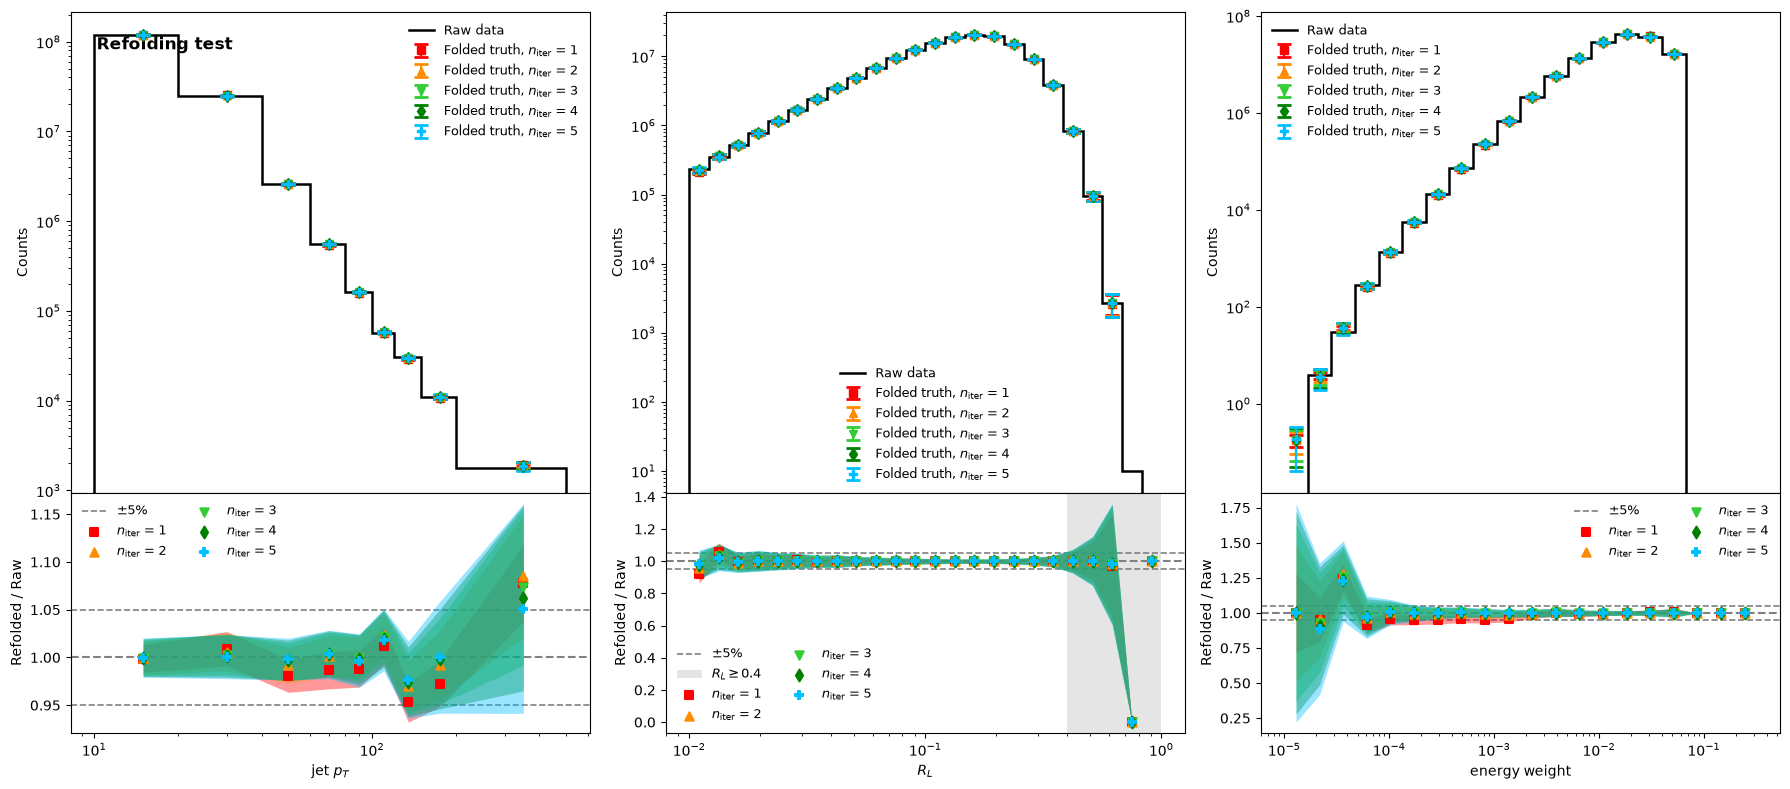

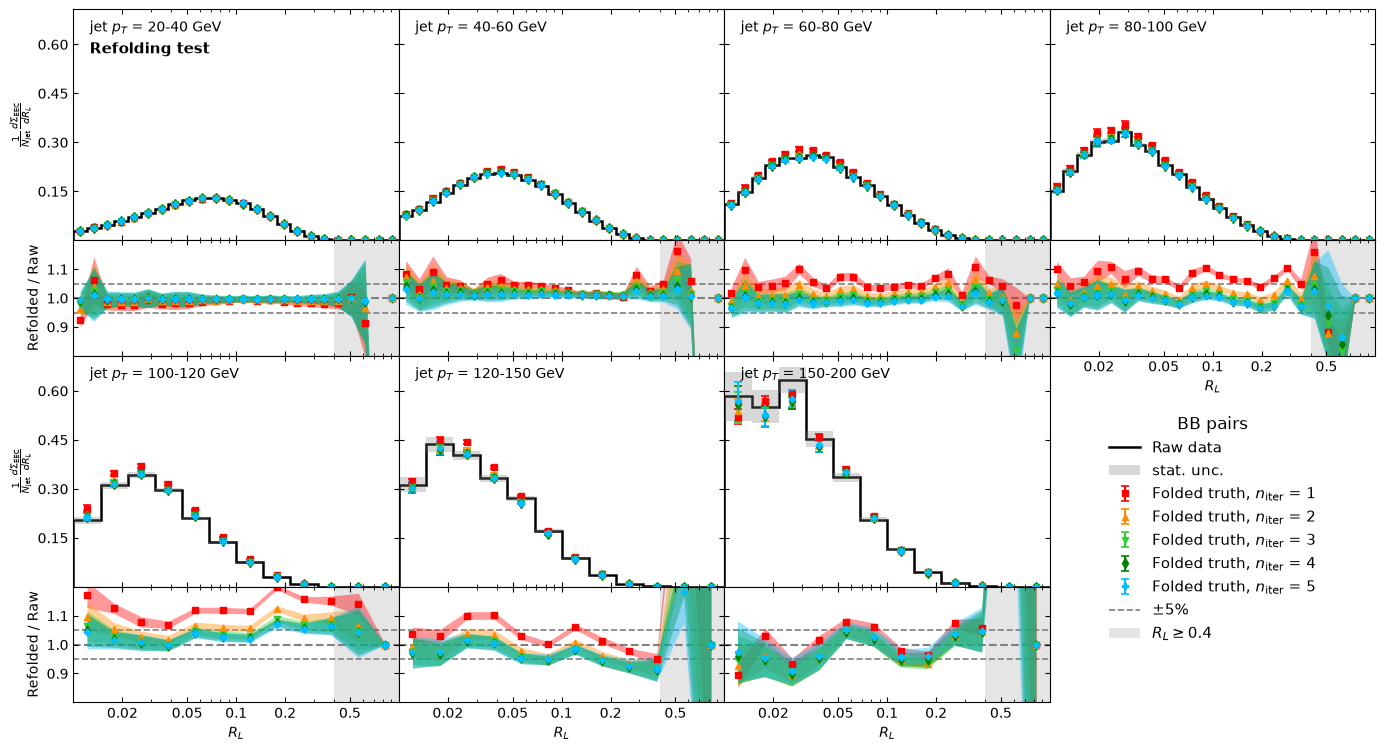

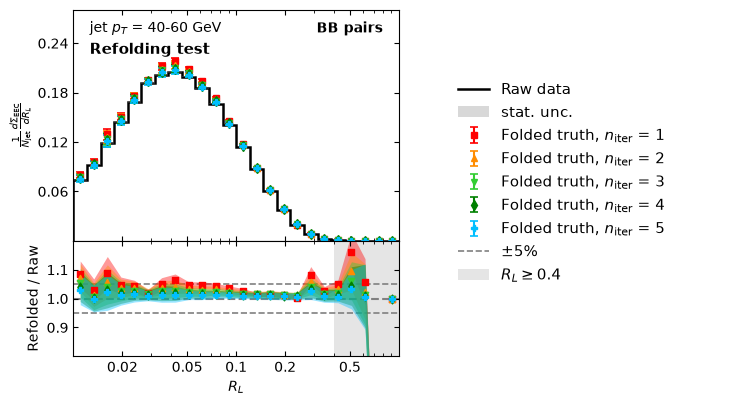

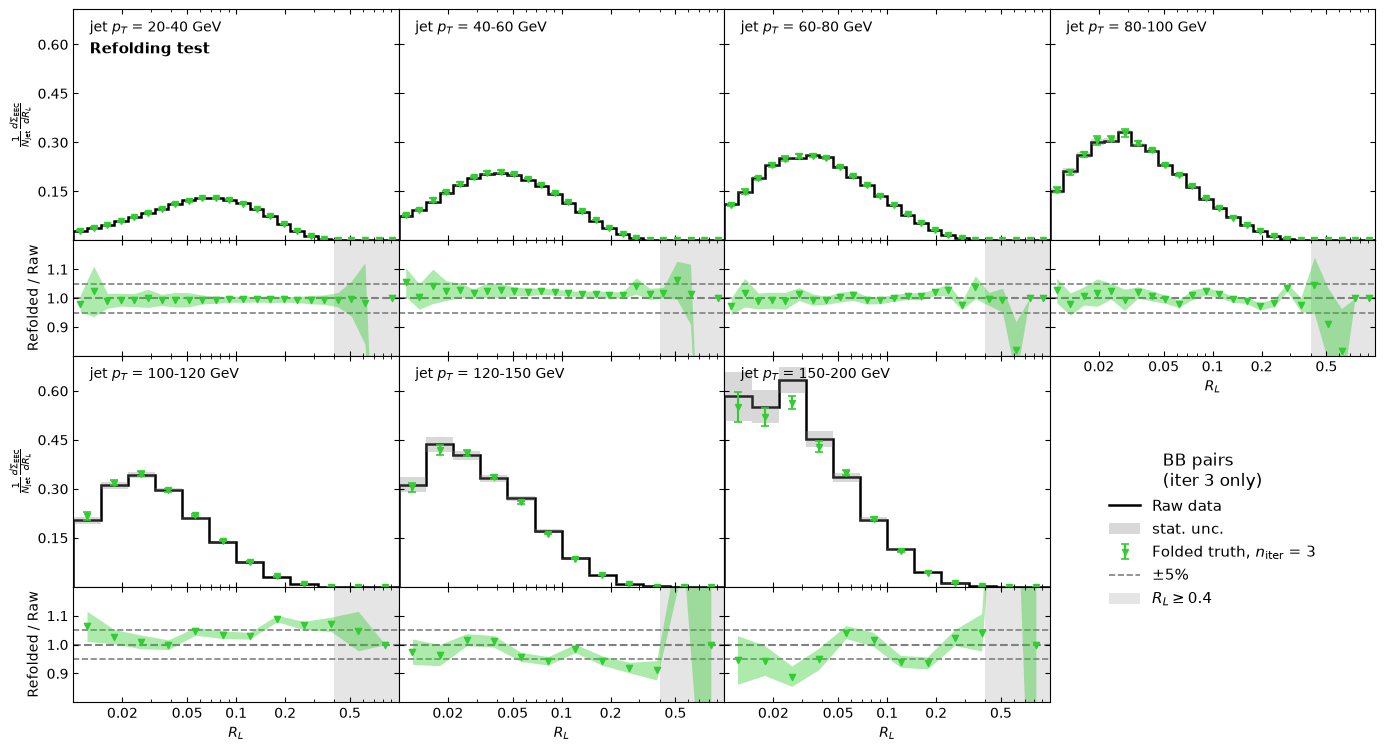

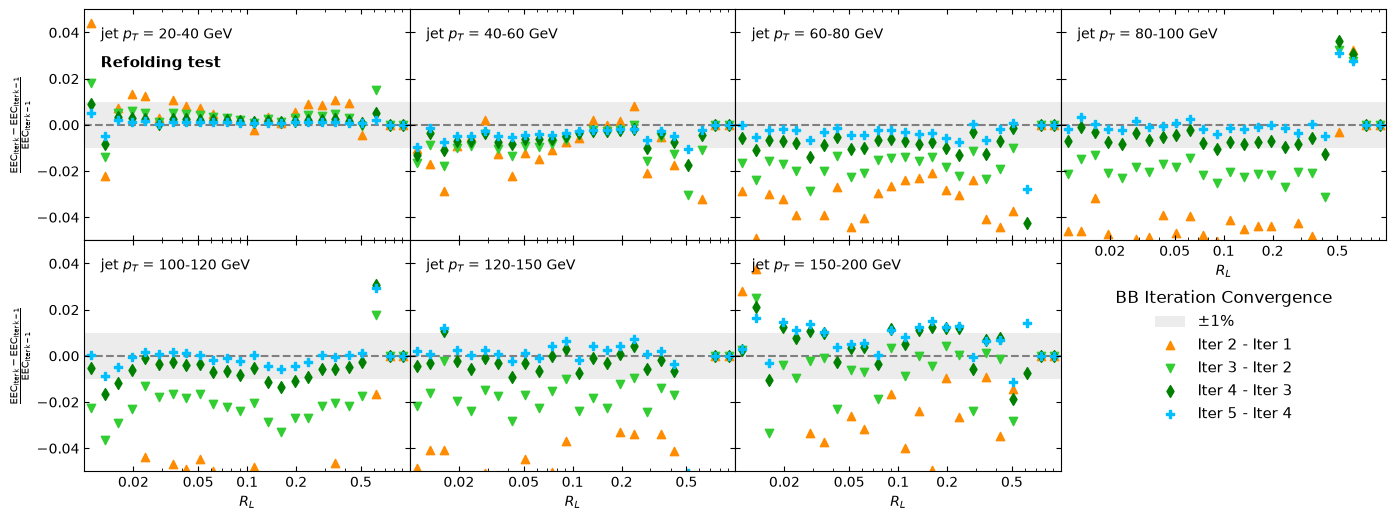

In [6]:
# Data refolding - BB - w/ purity corrections
lab = "BB"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False, closure_label="Refolding test")

# fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")

# differential pT bins (>= 100 GeV taken from the RL-rebinned files)
fig_ptbins = plot_closure_test_fullEEC_ptbins(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                              bincenters, binning, binwidths, L_colors, L_markers,
                                              unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                              high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")
fig_ptbins = plot_closure_test_fullEEC_ptbin(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                             bincenters, binning, binwidths, L_colors, L_markers, pt_bin_index=2,
                                             unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                             high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")

# same differential-pT plot, but only iteration 3
fig_ptbins_iter3 = plot_closure_test_fullEEC_ptbins_singleiter(
    lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
    bincenters, binning, binwidths, L_colors, L_markers,
    iteration=3, unfolding=False, label_ref="Raw data", label_test="Folded truth",
    high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test",
    extralabel="(iter 3 only)")

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")



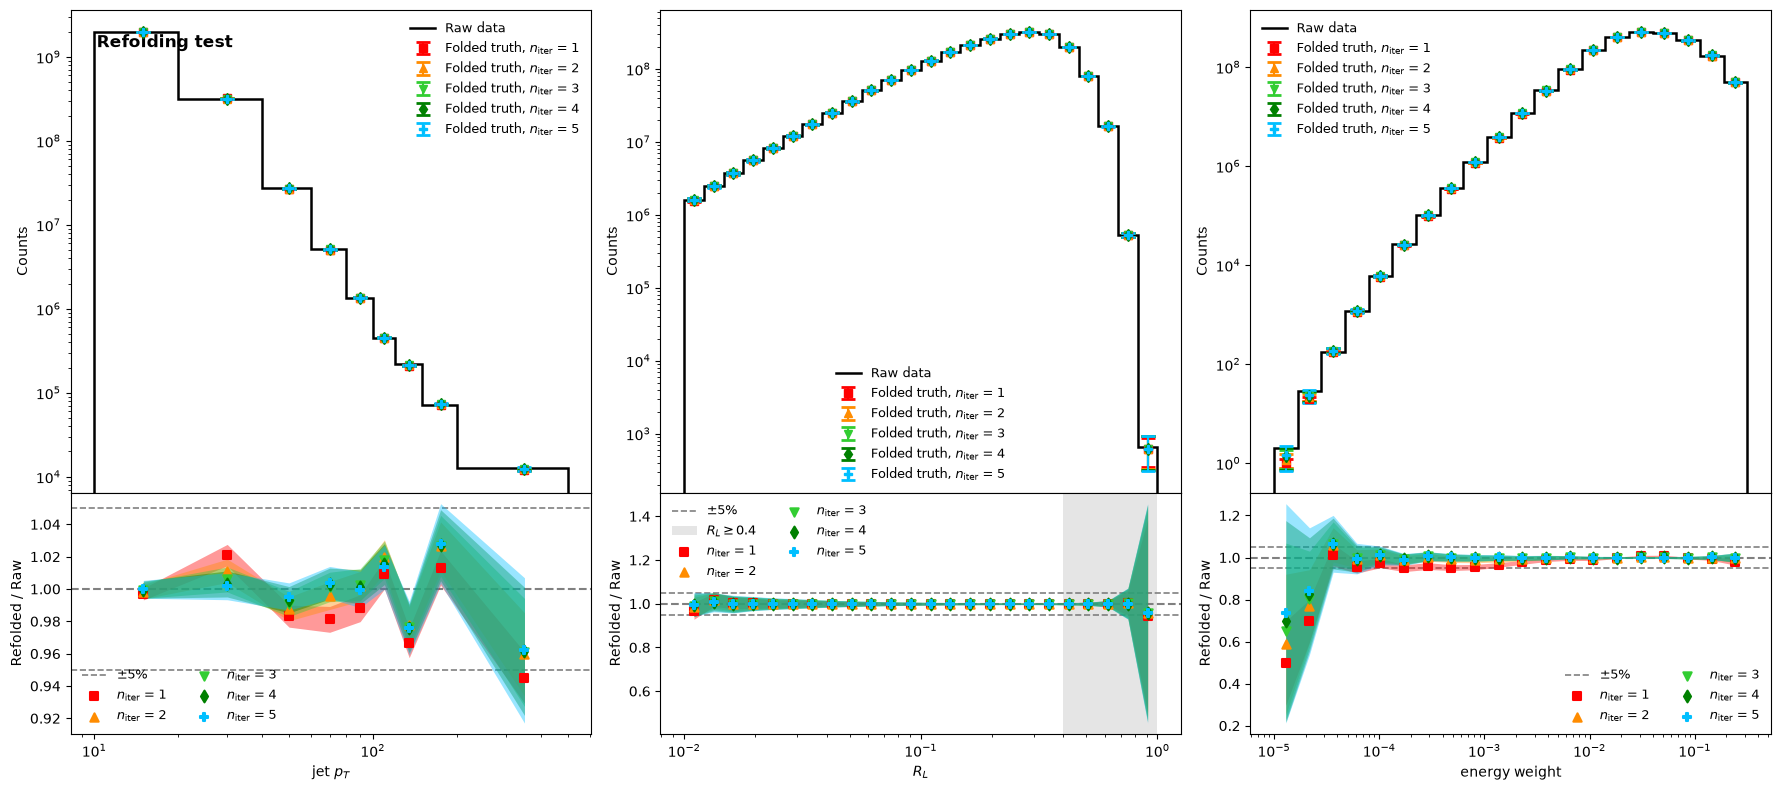

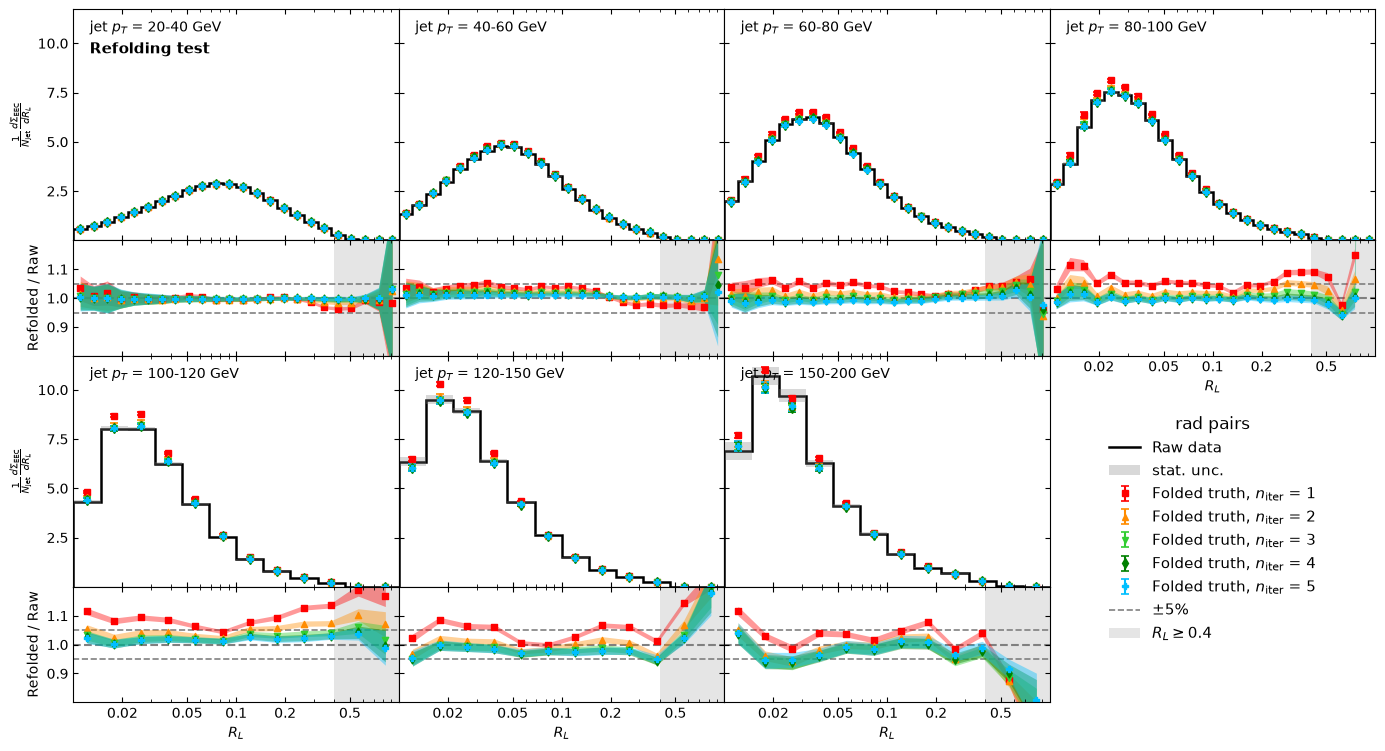

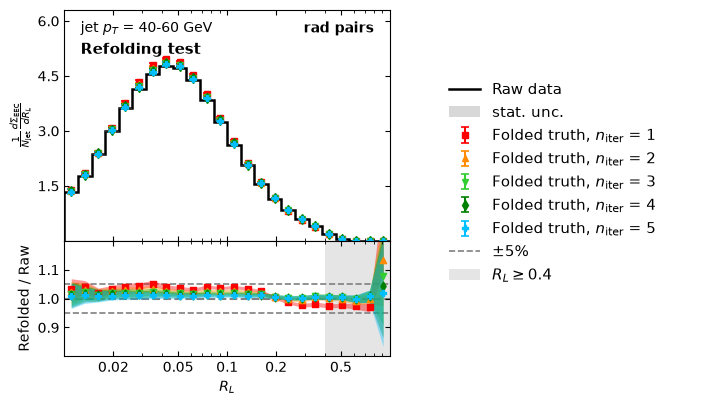

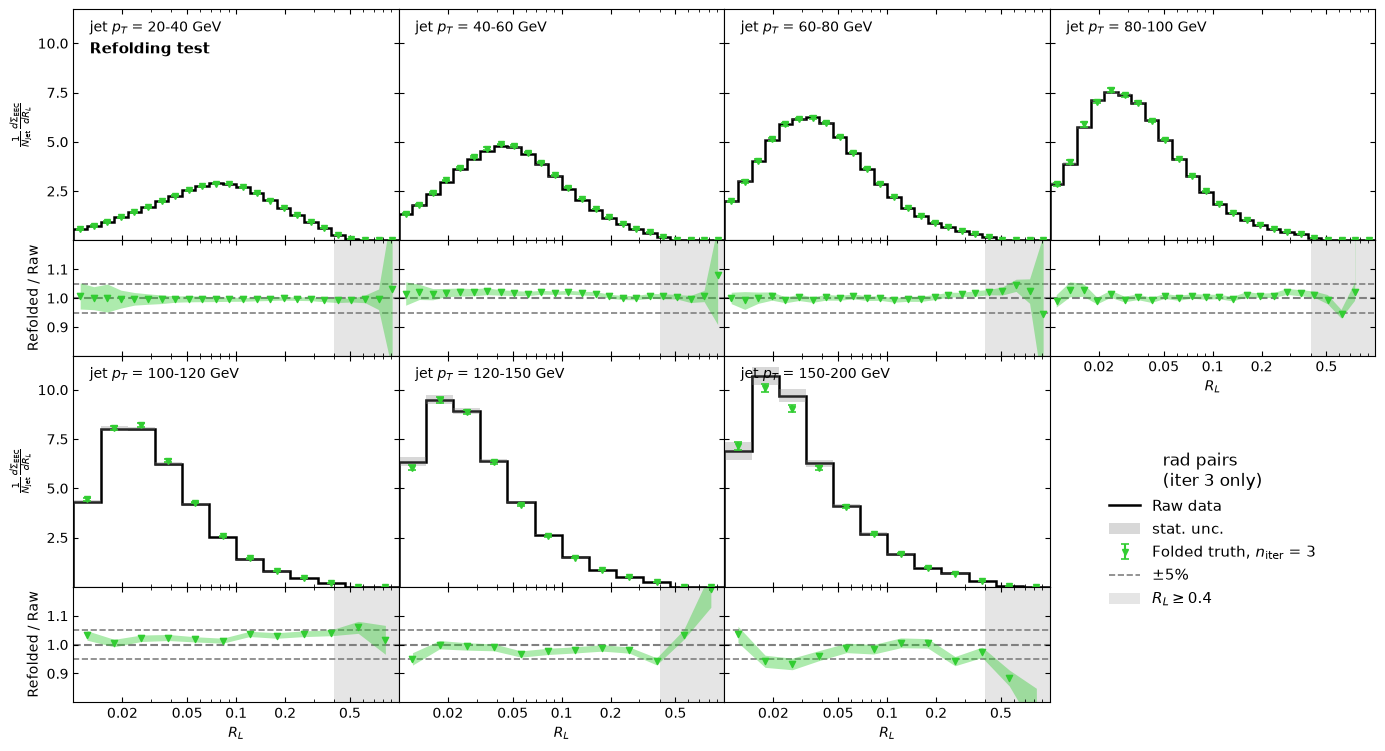

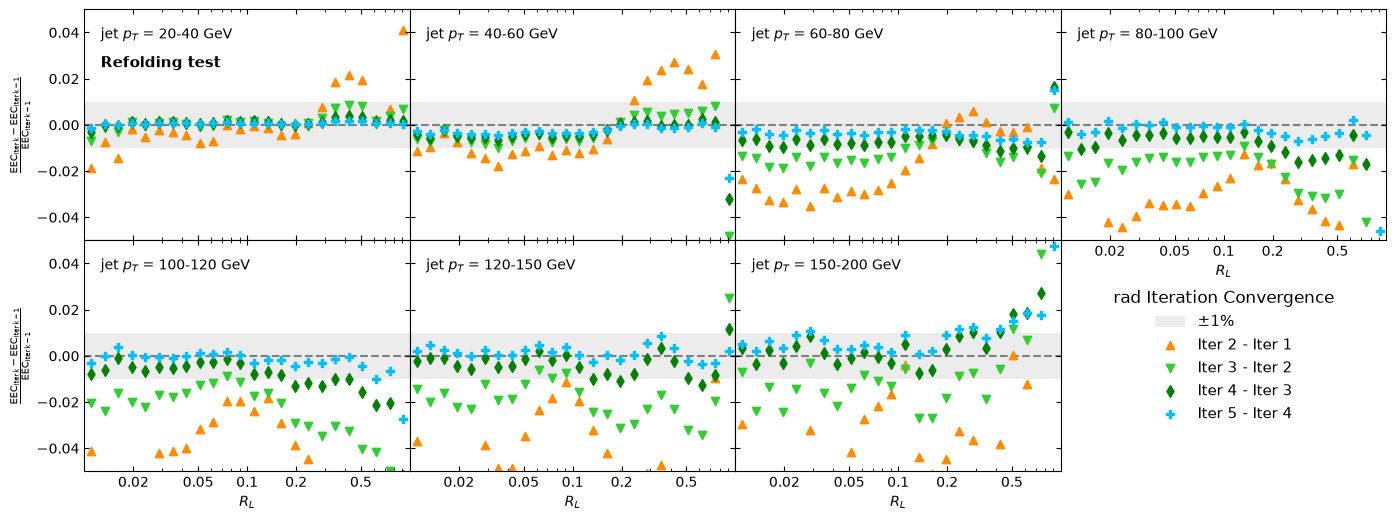

In [7]:
# Data refolding - rad - w/ purity corrections
lab = "rad"
y3_raw, y3_unfolded, y3_unfolded_err, y3_refolded, y3_refolded_err = get_yvals_for_label(lab)
plot_closure_test_axes_singleplot(n_iter, bincenters, binning, binwidths, y3_raw, y3_refolded, y3_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", unfolding=False, closure_label="Refolding test")

# fig = plot_closure_test_fullEEC(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")

# differential pT bins (>= 100 GeV taken from the RL-rebinned files)
fig_ptbins = plot_closure_test_fullEEC_ptbins(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                              bincenters, binning, binwidths, L_colors, L_markers,
                                              unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                              high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")
fig_ptbins = plot_closure_test_fullEEC_ptbin(lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
                                             bincenters, binning, binwidths, L_colors, L_markers, pt_bin_index=2,
                                             unfolding=False, label_ref="Raw data", label_test="Folded truth",
                                             high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test")

# same differential-pT plot, but only iteration 3
fig_ptbins_iter3 = plot_closure_test_fullEEC_ptbins_singleiter(
    lab, h3_raw[lab], h3_refolded[lab], h1_raw, h1_refolded,
    bincenters, binning, binwidths, L_colors, L_markers,
    iteration=3, unfolding=False, label_ref="Raw data", label_test="Folded truth",
    high_pt=inp.high_pt(lab, "refolding"), closure_label="Refolding test",
    extralabel="(iter 3 only)")

fig_delta = plot_refolding_iteration_deltas(lab, h3_refolded[lab], h1_refolded, bincenters, binning, binwidths, L_colors, L_markers, closure_label="Refolding test")


## Statistical Closure Test

Take the (matched) det-level MC --> smear it with data statistical errors --> unfold with original RM --> the resulting *unfolded* distribution gets compared to original truth-level MC 

Need:
- unfolded MC distribution (truth level)
- original (matched) truth-level MC

In [8]:
# MC 3D, unfolded, statistical closure test
h3_stat_unfolded_mc = {}
for lab in labels:
    for i in range(1, n_iter+1):
        if i == 1:
            h3_stat_unfolded_mc[lab] = []
        h3_stat_unfolded_mc[lab].append(f_closure_tests[f"statistical_closure/Statistical_{lab}_Unfolded_iter{i}"])
        
# MC 1D, unfolded, statistical closure test
h1_stat_unfolded_mc = []
for i in range(1, n_iter+1):
    h1_stat_unfolded_mc.append(f_closure_tests_1D["statistical_closure/Statistical_Unfolded1Diter{}".format(i)])

# Returns y3_gen_matched (values for one histogram), and y3_unfolded_mc (array of histograms for each iteration)
def get_yvals_per_label_statclosure(lab):
    y3_stat_unfolded_mc = [proj3D(a) for a in h3_stat_unfolded_mc[lab]]
    y3_stat_unfolded_mc_err = [proj3D_err(a) for a in h3_stat_unfolded_mc[lab]]

    y3_gen_matched = proj3D(h3_truth[lab])          # was: proj3D(h3_gen_matched[lab])

    return y3_stat_unfolded_mc, y3_stat_unfolded_mc_err, y3_gen_matched



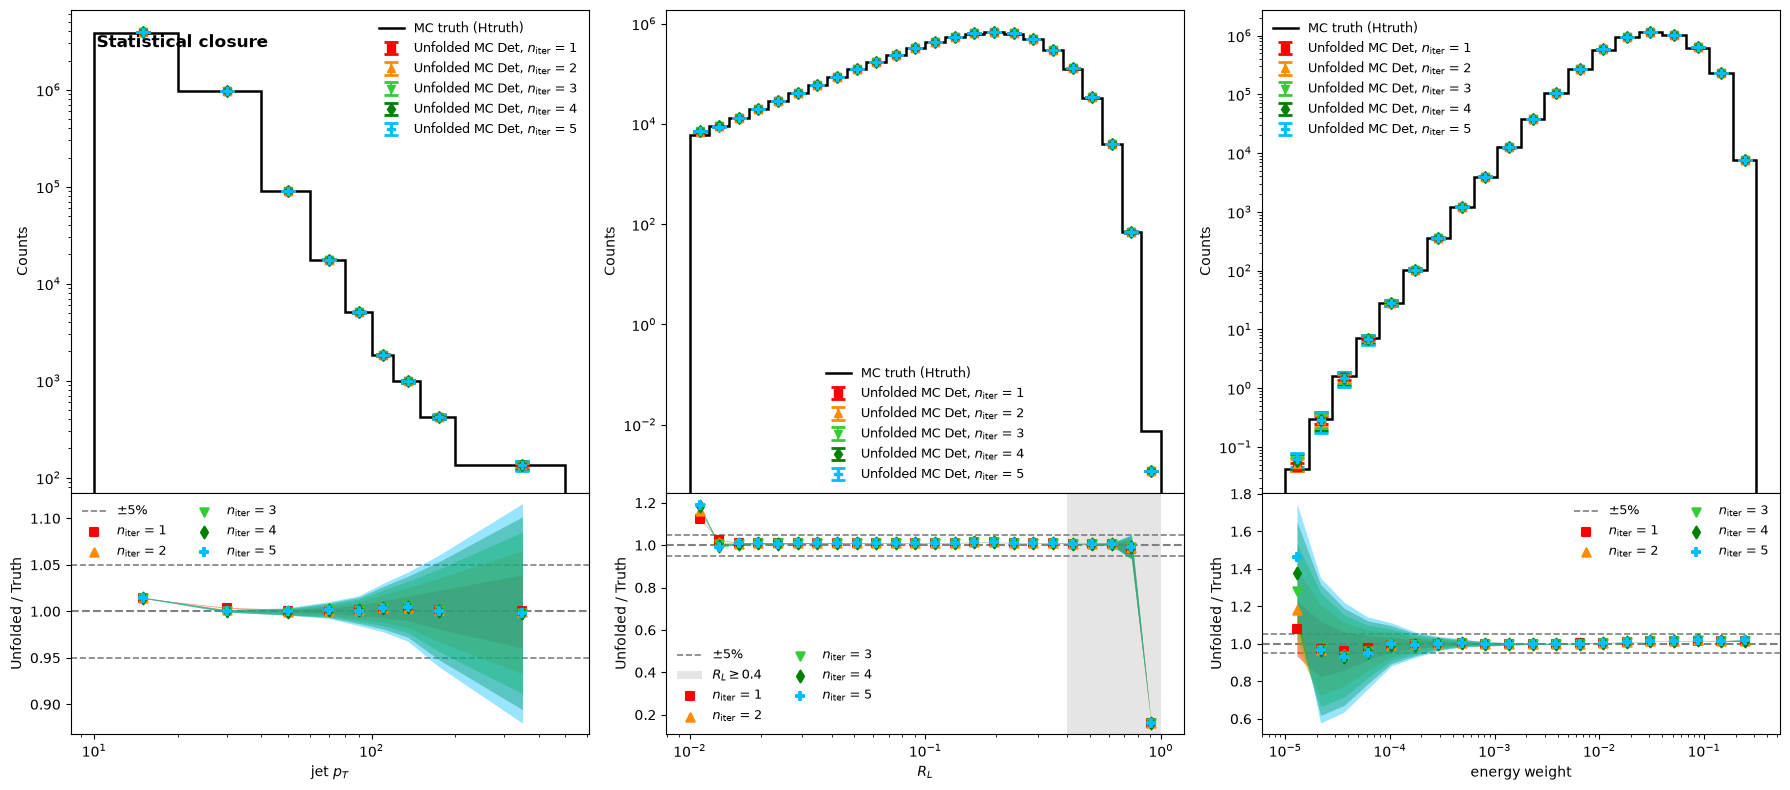

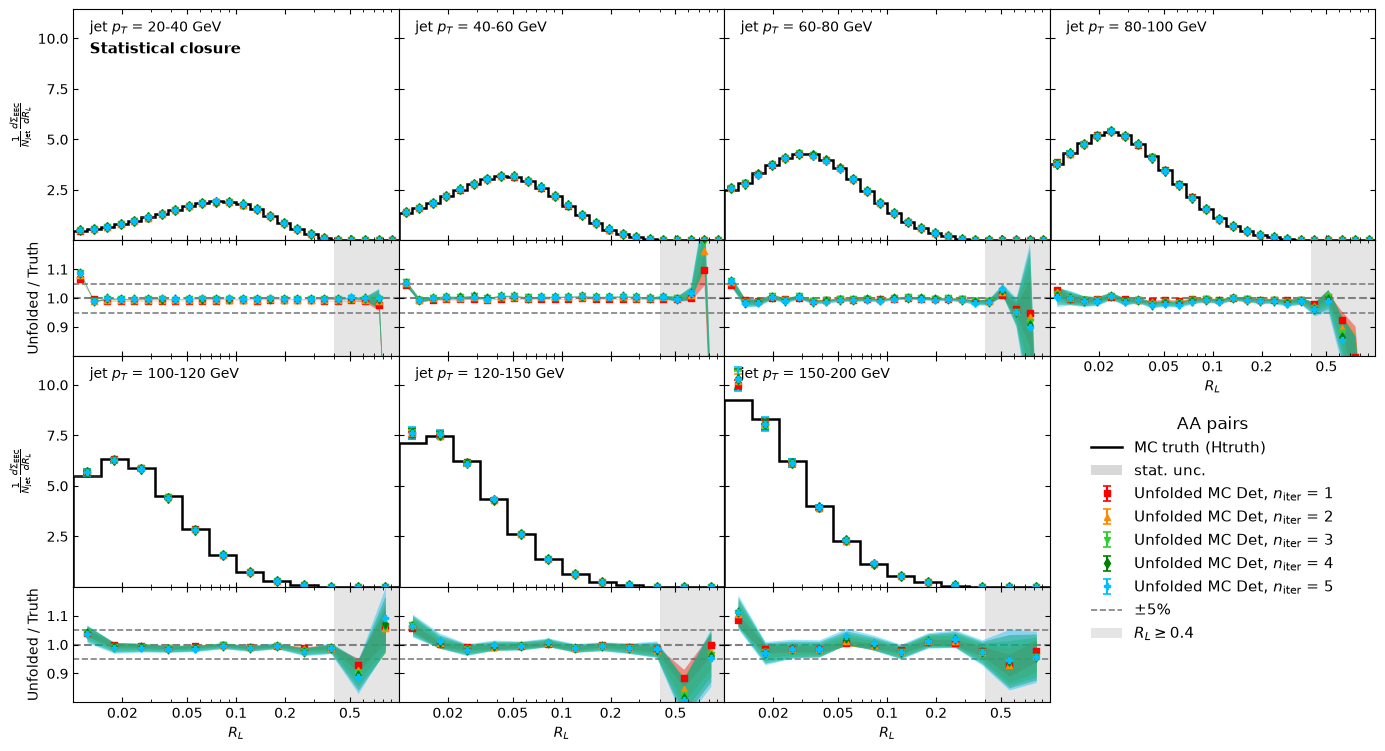

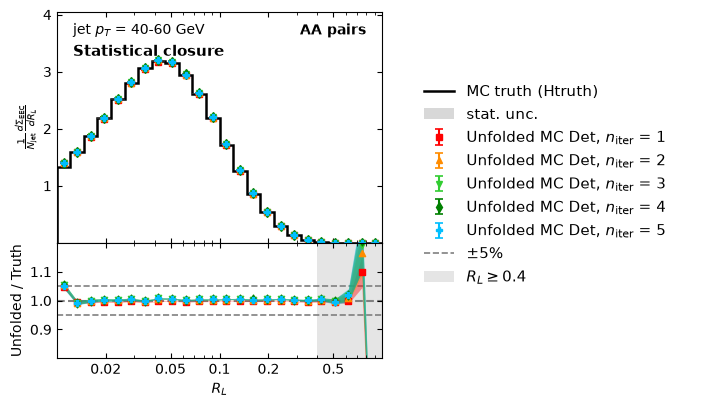

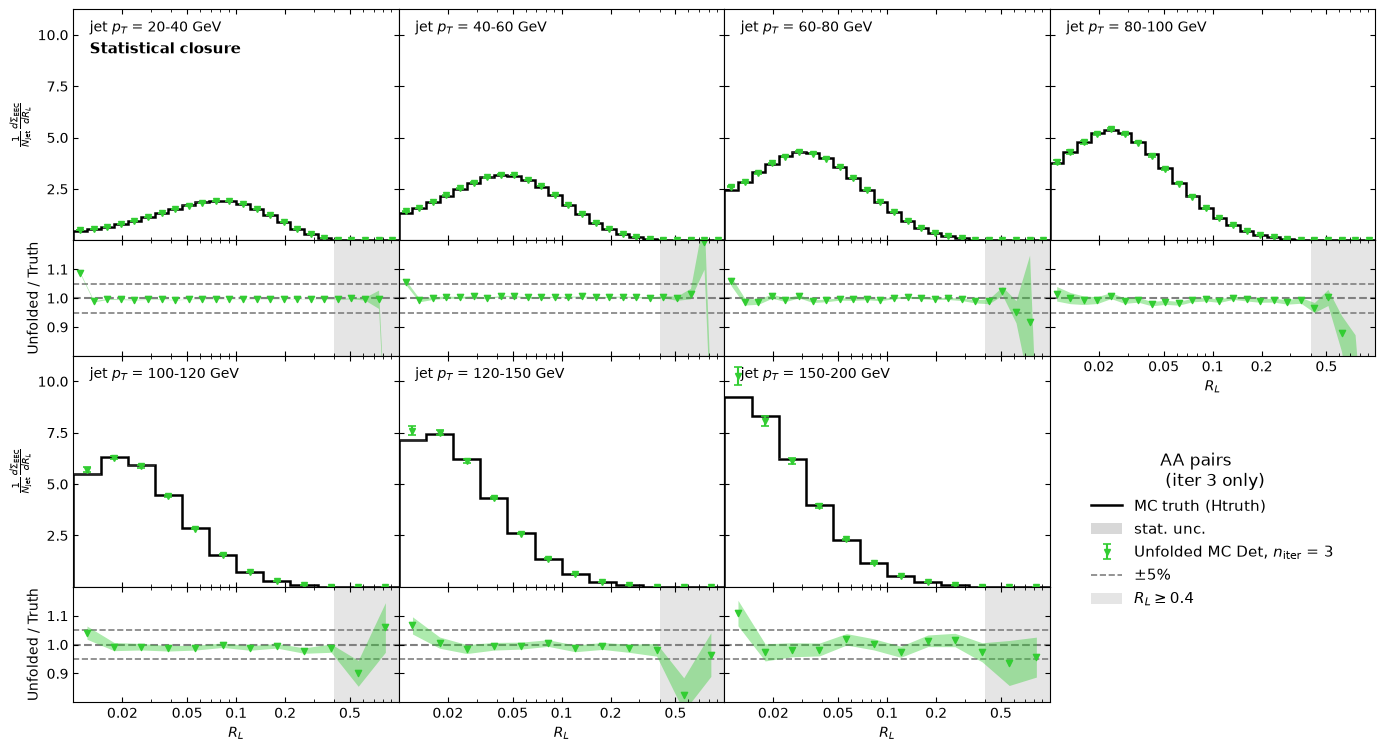

(<Figure size 1680x900 with 15 Axes>,
 <Figure size 840x450 with 3 Axes>,
 <Figure size 1680x900 with 15 Axes>)

In [9]:
# Statistical closure
lab = "AA"

plot_closure_section(lab, "statistical", h3_truth[lab], h3_stat_unfolded_mc[lab],
                     "MC truth (Htruth)", inp, pt_bin_index=2)

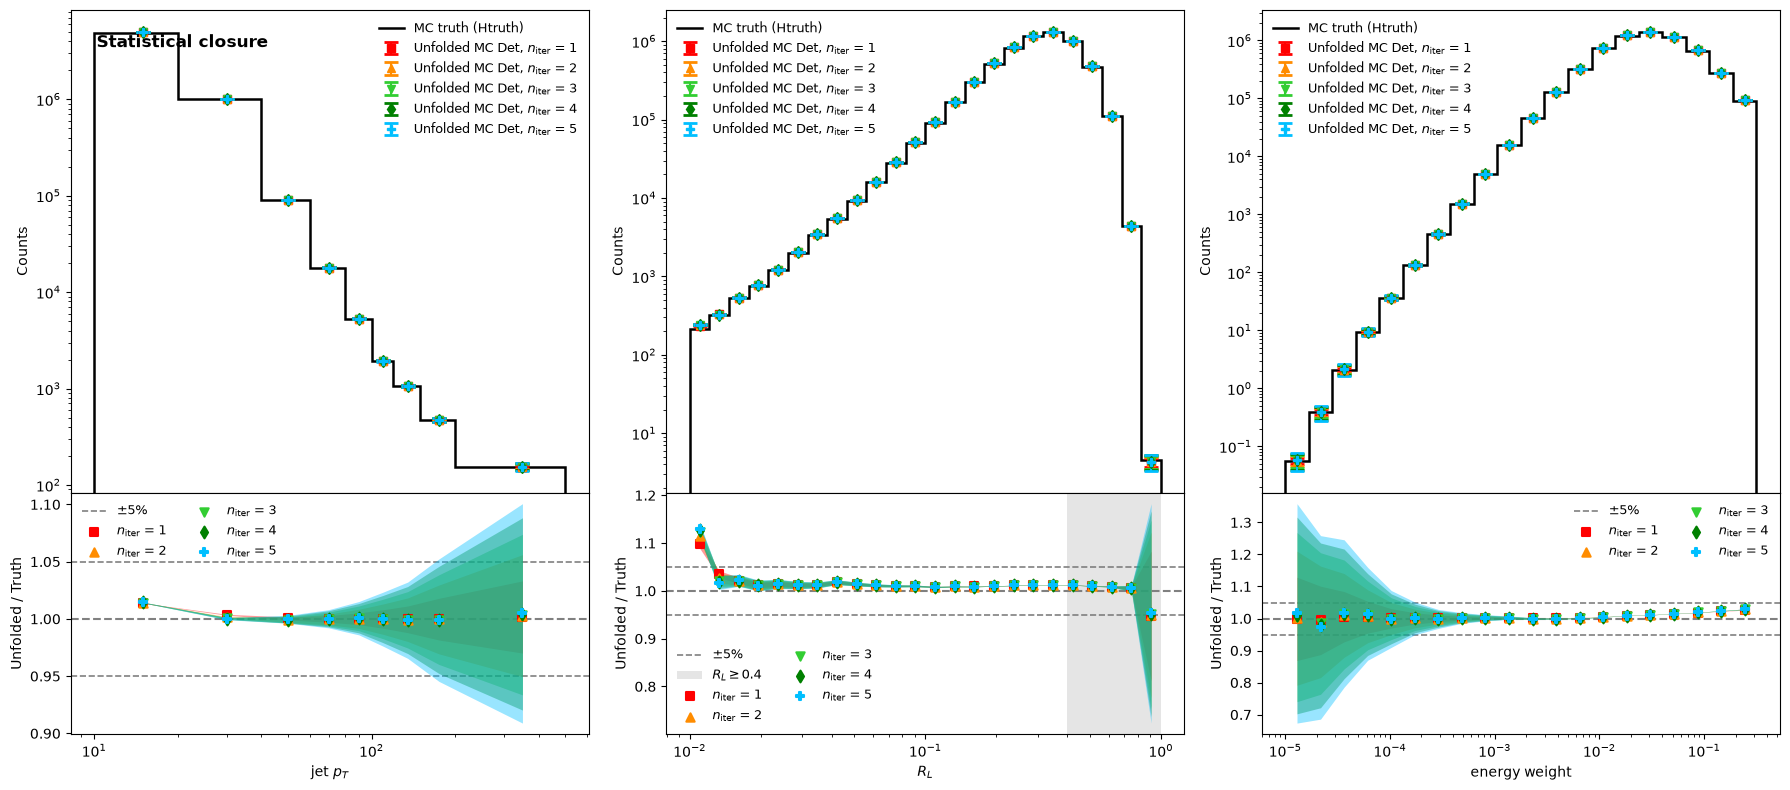

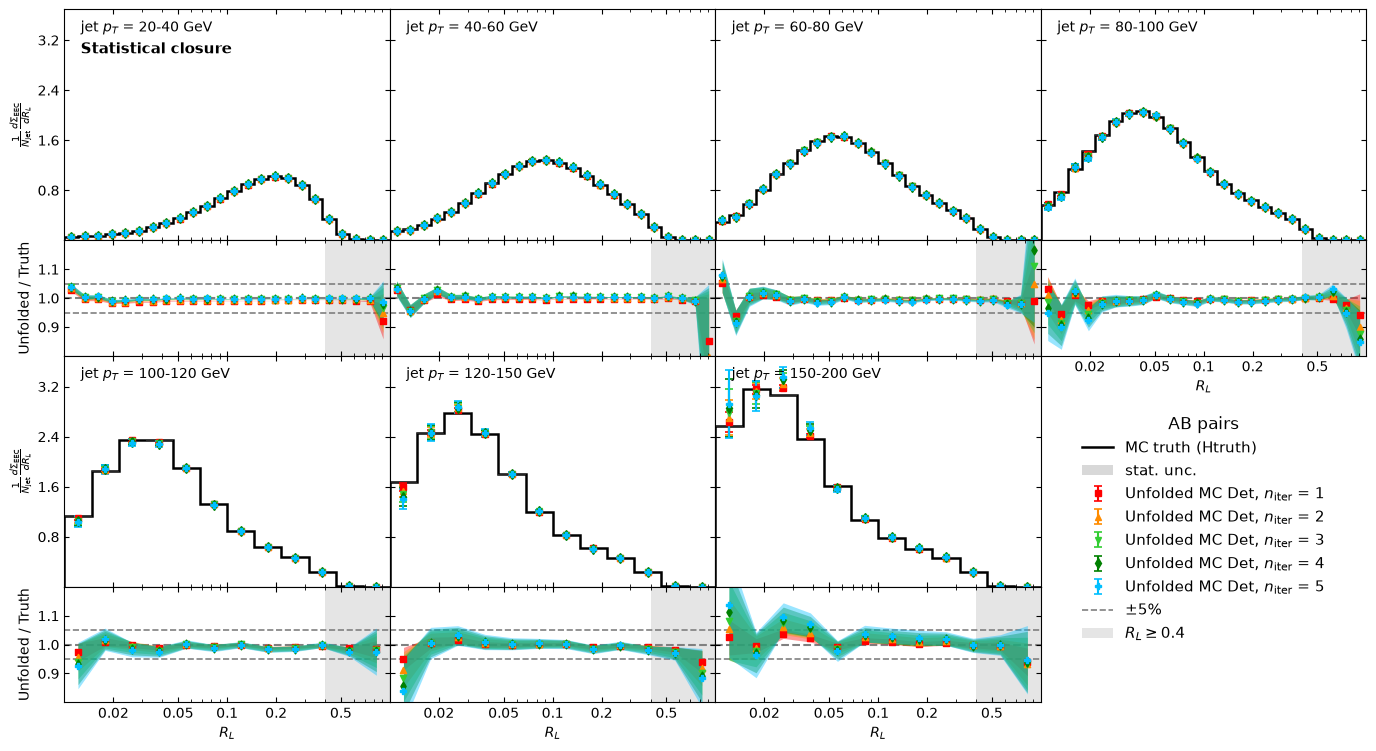

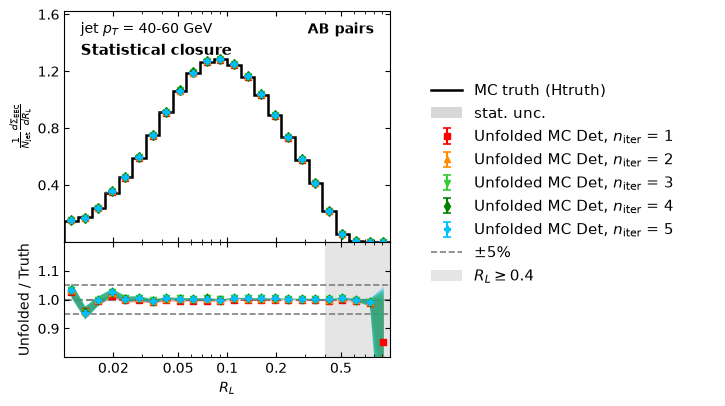

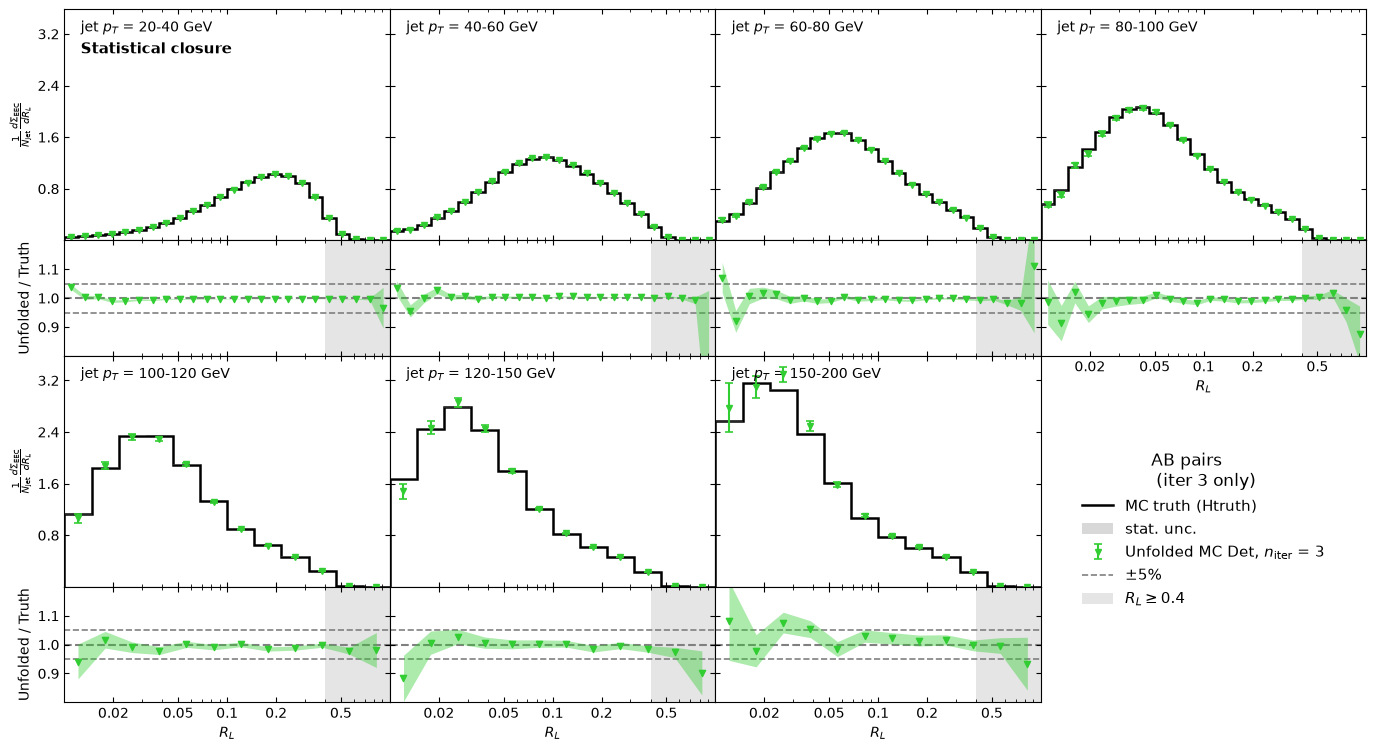

(<Figure size 1680x900 with 15 Axes>,
 <Figure size 840x450 with 3 Axes>,
 <Figure size 1680x900 with 15 Axes>)

In [10]:
# Statistical closure
lab = "AB"

plot_closure_section(lab, "statistical", h3_truth[lab], h3_stat_unfolded_mc[lab],
                     "MC truth (Htruth)", inp, pt_bin_index=2)

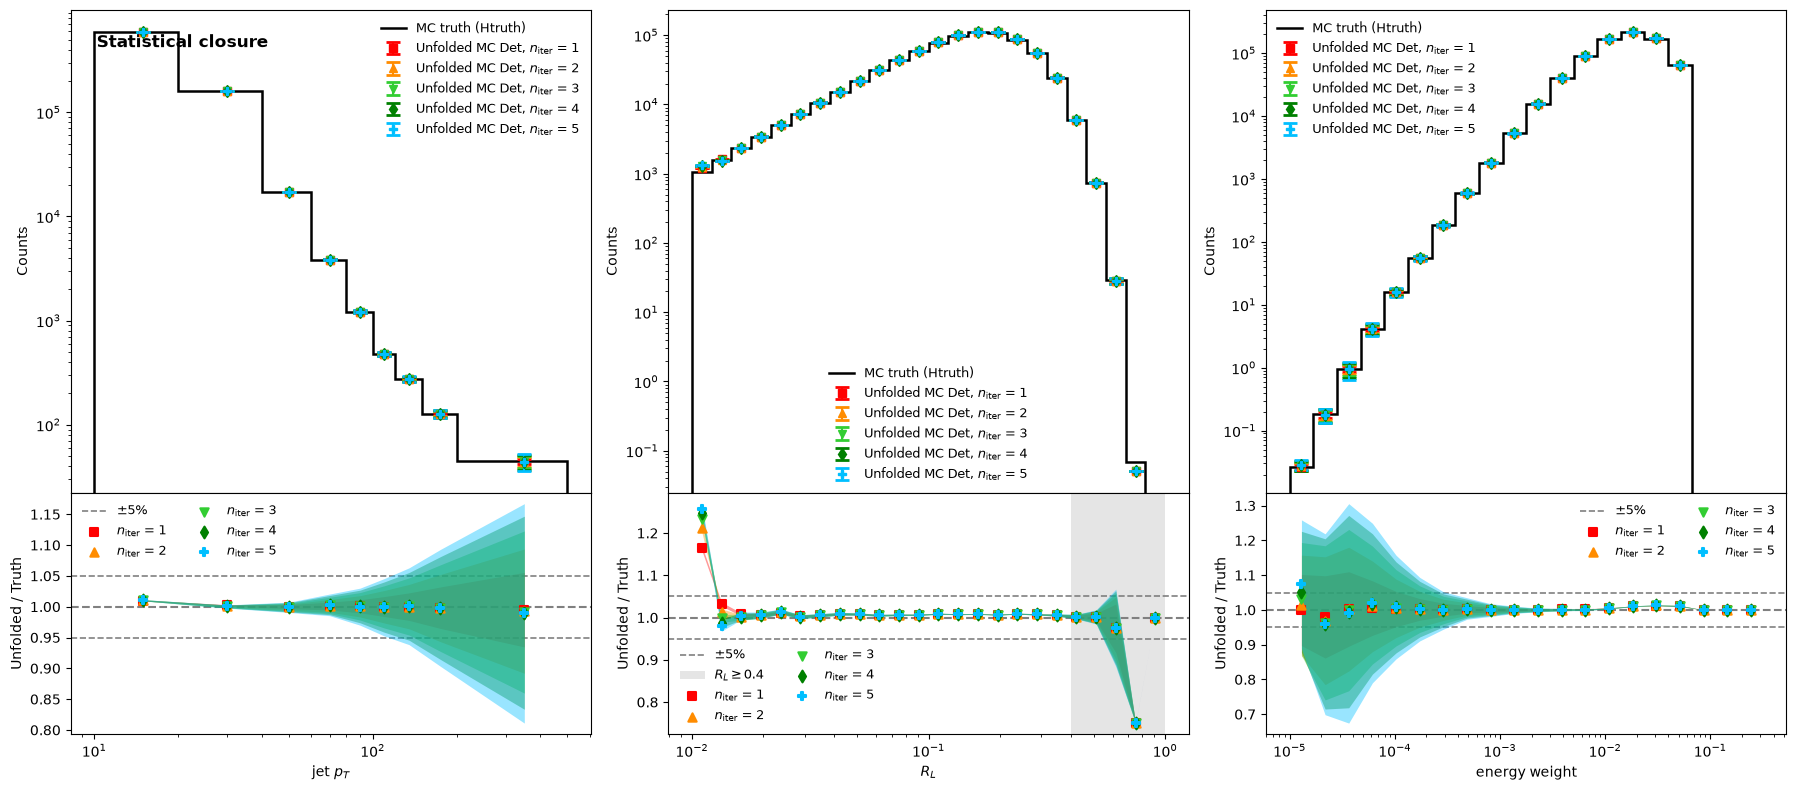

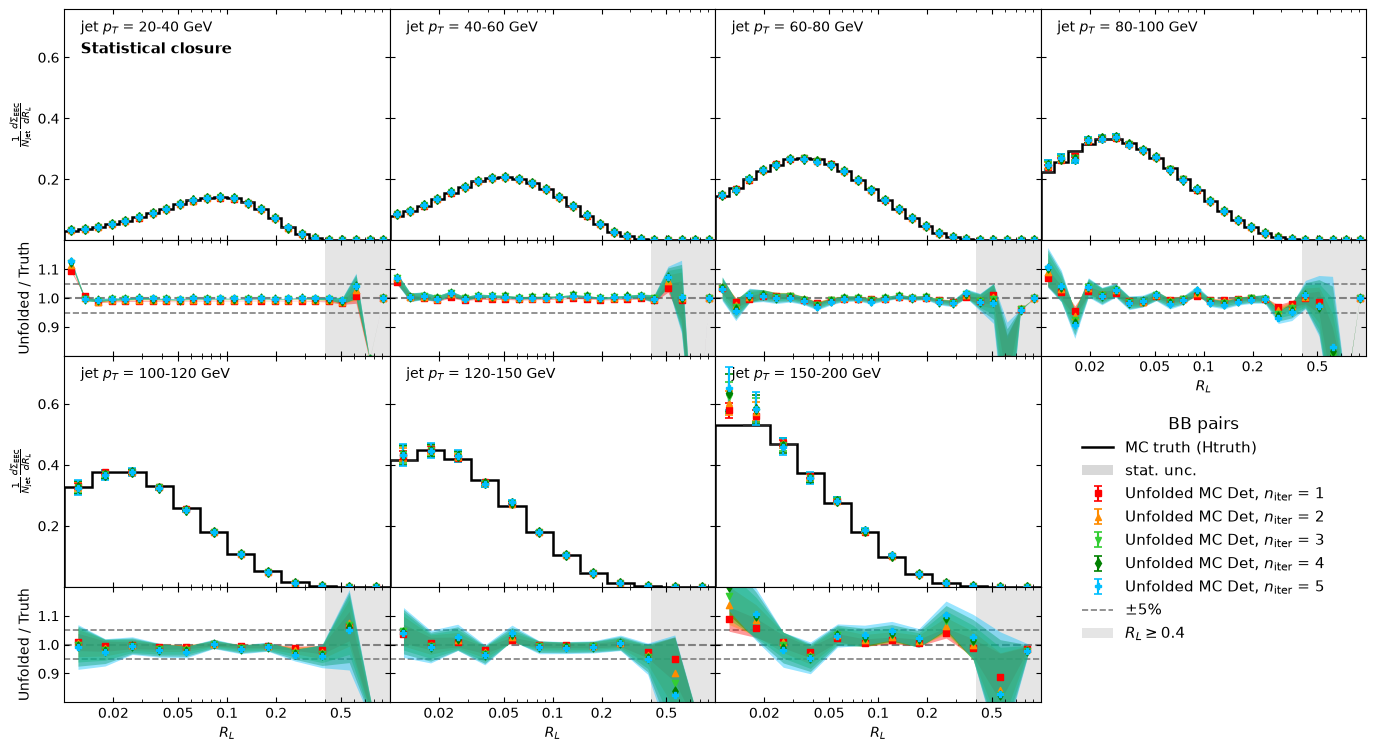

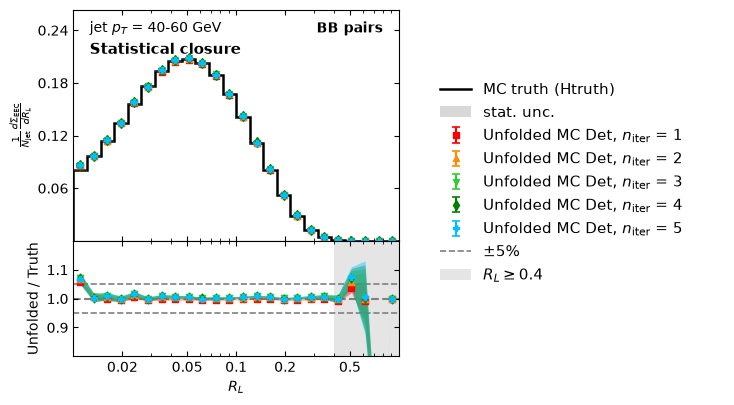

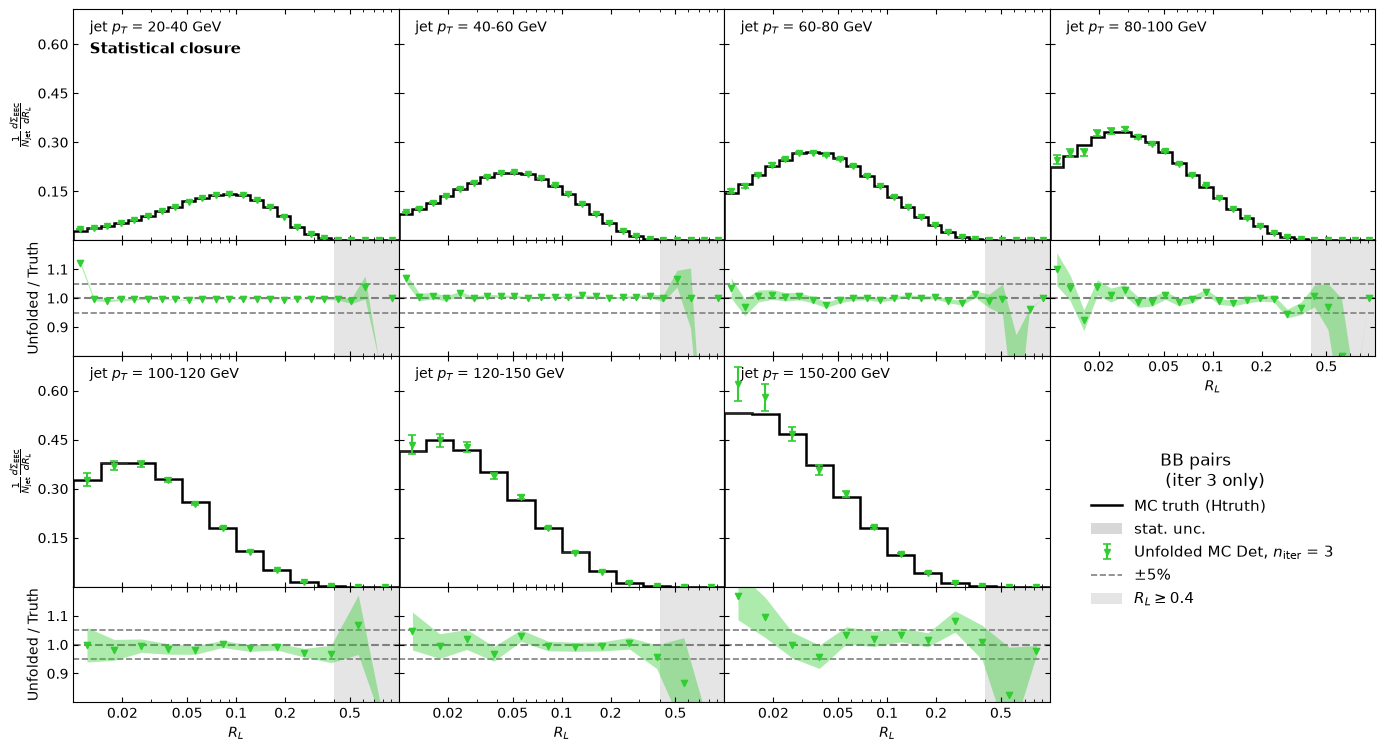

(<Figure size 1680x900 with 15 Axes>,
 <Figure size 840x450 with 3 Axes>,
 <Figure size 1680x900 with 15 Axes>)

In [11]:
# Statistical closure
lab = "BB"

plot_closure_section(lab, "statistical", h3_truth[lab], h3_stat_unfolded_mc[lab],
                     "MC truth (Htruth)", inp, pt_bin_index=2)

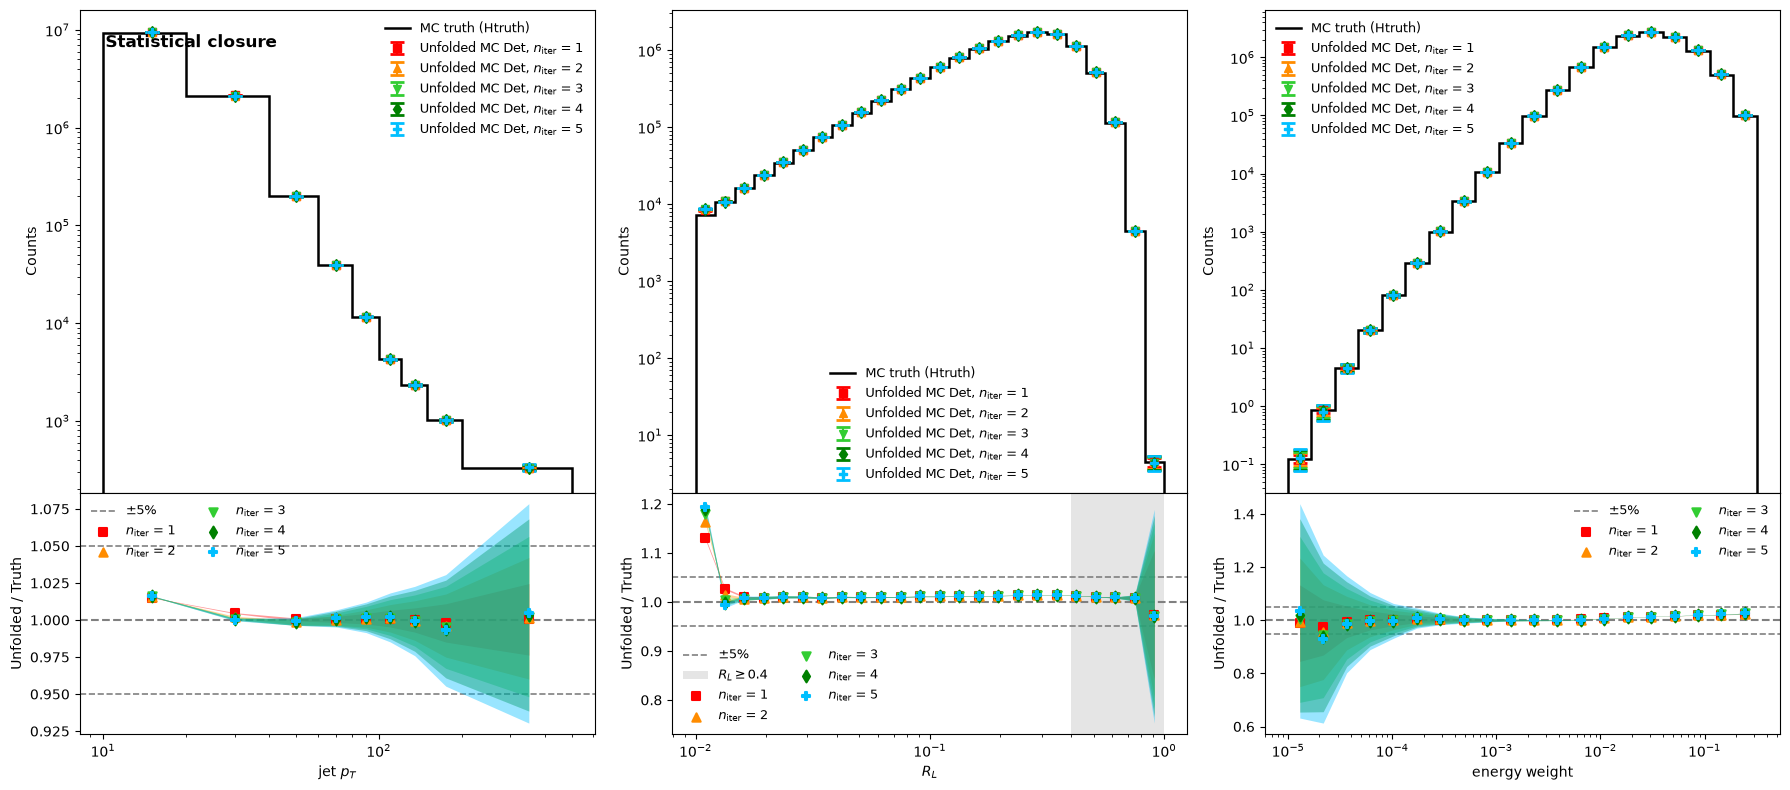

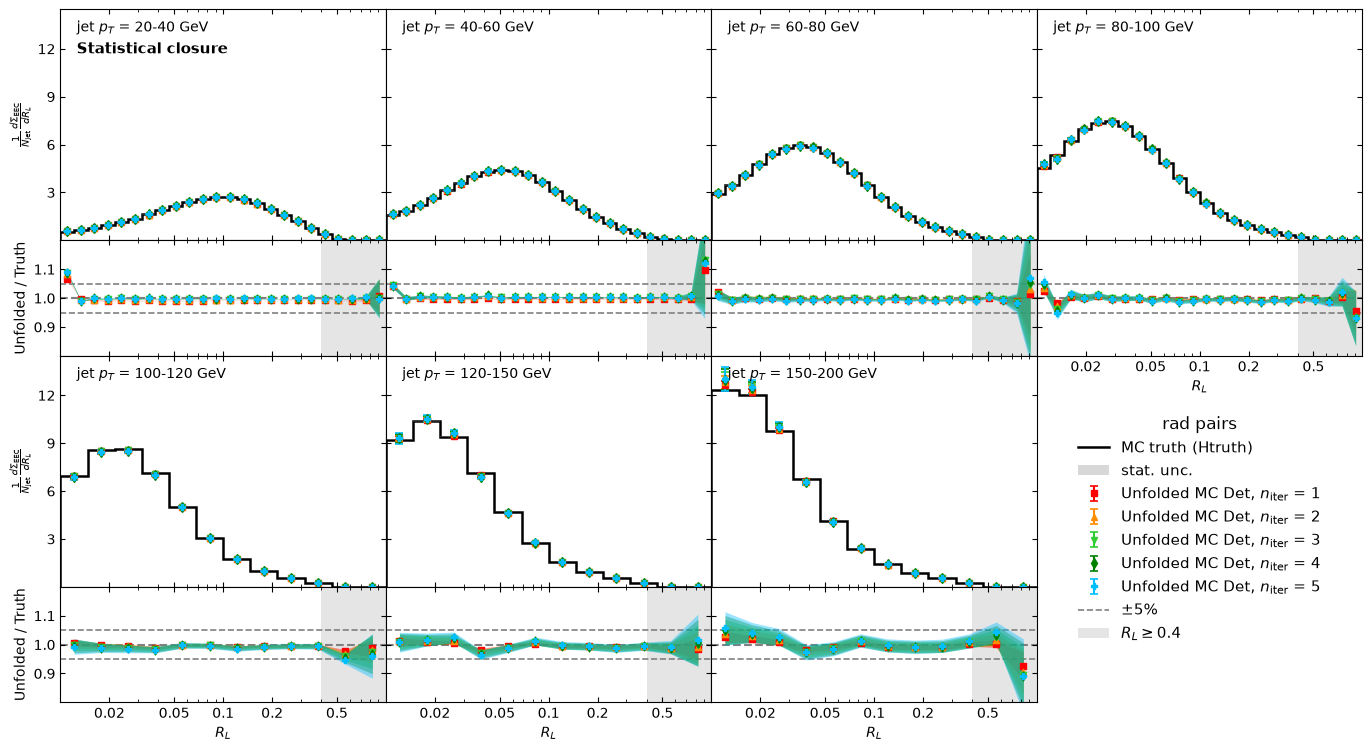

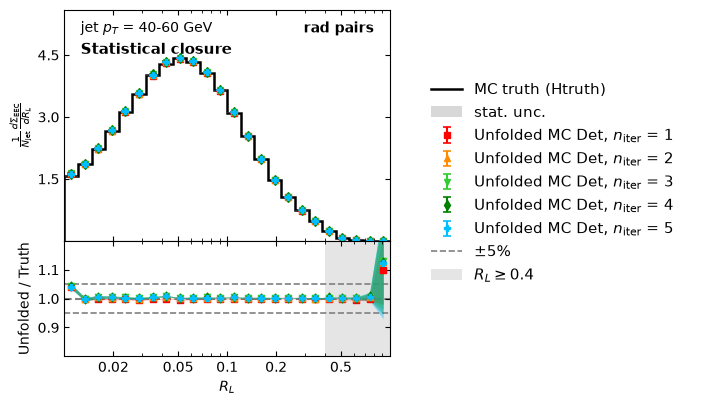

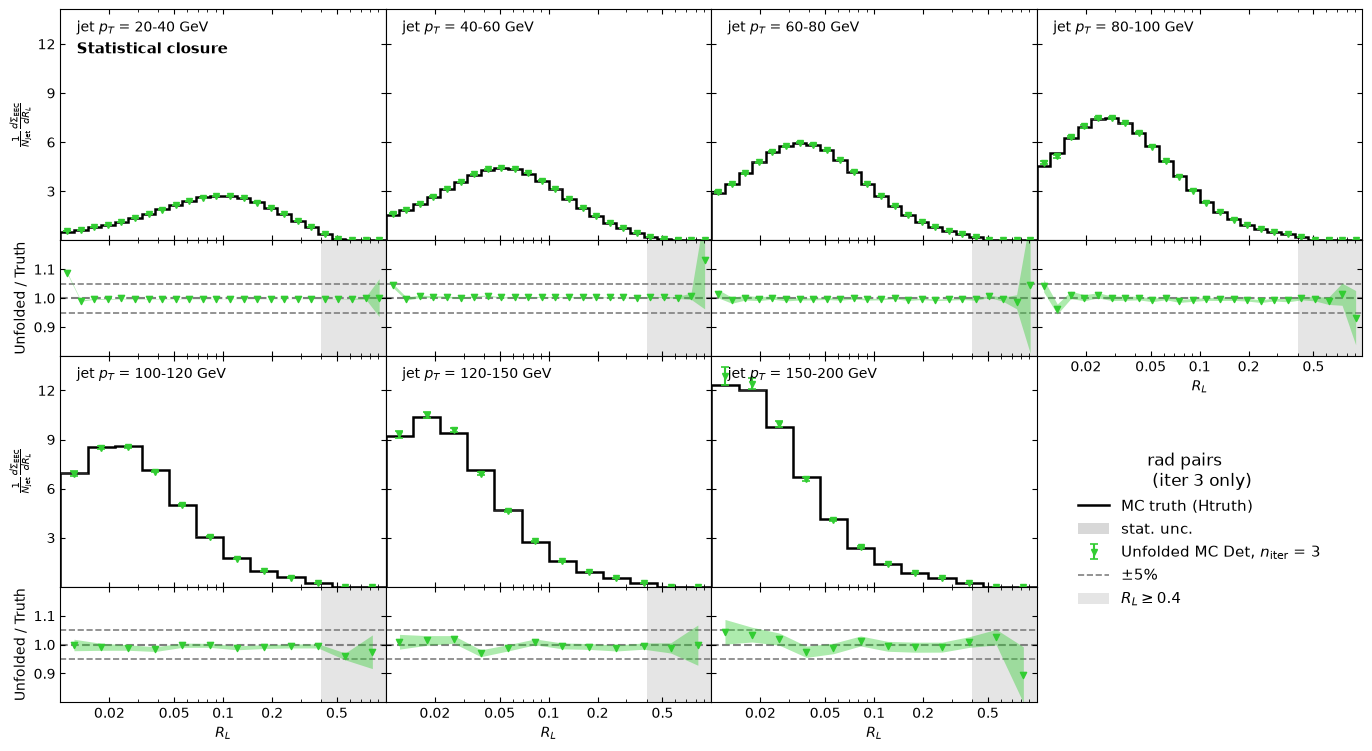

(<Figure size 1680x900 with 15 Axes>,
 <Figure size 840x450 with 3 Axes>,
 <Figure size 1680x900 with 15 Axes>)

In [12]:
# Statistical closure
lab = "rad"

plot_closure_section(lab, "statistical", h3_truth[lab], h3_stat_unfolded_mc[lab],
                     "MC truth (Htruth)", inp, pt_bin_index=2)